# Machine Learning - Bike-Sharing Availability Prediction (Vélib’ Métropole)

## Objectif du notebook

Ce notebook est consacré à la conception, à l'entraînement et à l'évaluation de modèles de Machine Learning capables de prédire la disponibilité des vélos dans les stations.

L'objectif est de développer un modèle capable d'anticiper les stations susceptibles de devenir vides à un horizon de 30 minutes, afin d'améliorer l'expérience utilisateur et d'anticiper les problèmes de disponibilité.

La démarche suivra les étapes suivantes :

1. Préparation et vérification des données destinées à la modélisation.
2. Définition de la variable cible et construction du jeu de données supervisé.
3. Feature Engineering : création de variables temporelles, historiques et comportementales.
4. Découpage chronologique des données en ensembles d'entraînement, de validation et de test.
5. Construction de modèles de référence (baselines).
6. Entraînement et optimisation de plusieurs algorithmes de Machine Learning.
7. Évaluation approfondie des modèles à l'aide de métriques adaptées.
8. Comparaison des performances et sélection du meilleur modèle.
9. Analyse des erreurs, interprétabilité et limites du modèle.

**Principe méthodologique :** toutes les étapes respecteront la dimension temporelle du problème afin d'éviter toute fuite de données (*data leakage*) et de reproduire des conditions proches d'une utilisation réelle.

## 1. Imports et configuration

Cette première étape consiste à importer les bibliothèques nécessaires au prétraitement des données, à la construction des modèles de Machine Learning et à leur évaluation.

Nous définissons également les paramètres généraux du projet afin de garantir la reproductibilité des expérimentations.

In [1]:
# Manipulation des données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Séparation et validation
from sklearn.model_selection import TimeSeriesSplit

# Modèles de Machine Learning
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# Évaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Reproductibilité
RANDOM_STATE = 42

# Affichage
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

sns.set_theme(style="whitegrid")

print("Environnement initialisé.")

Environnement initialisé.


## 2. Chargement et préparation initiale des données

Les données proviennent de fichiers JSON compressés (`.json.gz`), organisés par journée dans le dossier `data/raw`.

Nous limitons l'analyse à la période du 24 au 31 octobre 2026, car les autres journées ne couvrent que certaines heures et non des journées complètes. Cela permet de travailler sur des données plus homogènes et d'éviter de biaiser les analyses temporelles et l'apprentissage du modèle.

Les données sont ensuite regroupées dans un DataFrame unique.

Les horodatages d'origine sont conservés en UTC. Une colonne supplémentaire, `temps`, est créée en heure de Paris et arrondie aux intervalles de cinq minutes afin de faciliter les analyses temporelles.

In [2]:
import os
import glob
import gzip
import json
import re

from pathlib import Path

# --------------------------------------------------
# 1. Configuration des chemins et de la période
# --------------------------------------------------

DATE_DEBUT = "2026-10-24"
DATE_FIN = "2026-10-31"

if os.path.exists("../data/raw"):
    DOSSIER = ".."                 # Notebook dans notebooks/
elif os.path.exists("data/raw"):
    DOSSIER = "."                  # Notebook à la racine
else:
    if not os.path.exists("velib-kit-data-science"):
        os.system(
            "git clone --depth 1 "
            "https://github.com/G-Akram01/velib-kit-data-science.git"
        )
    DOSSIER = "velib-kit-data-science"

print("Dossier du projet :", DOSSIER)

# --------------------------------------------------
# 2. Sélection des fichiers de la période
# --------------------------------------------------

tous_les_fichiers = sorted(
    glob.glob(f"{DOSSIER}/data/raw/*/*.json.gz")
)

date_debut = pd.Timestamp(DATE_DEBUT)
date_fin = pd.Timestamp(DATE_FIN)

fichiers = []

for chemin in tous_les_fichiers:
    correspondance = re.search(r"\d{4}-\d{2}-\d{2}", chemin)

    if correspondance:
        date_fichier = pd.Timestamp(correspondance.group())

        if date_debut <= date_fichier <= date_fin:
            fichiers.append(chemin)

print("Nombre total de fichiers trouvés :", len(tous_les_fichiers))
print("Nombre de fichiers sélectionnés :", len(fichiers))

if not fichiers:
    raise FileNotFoundError(
        "Aucun fichier trouvé pour la période demandée. "
        "Vérifie la structure de data/raw."
    )

# --------------------------------------------------
# 3. Lecture des fichiers JSON compressés
# --------------------------------------------------

def lire_json_gz(chemin):
    with gzip.open(chemin, "rt", encoding="utf-8") as f:
        return json.load(f)

morceaux = []

for chemin in fichiers:
    contenu = lire_json_gz(chemin)

    stations = pd.DataFrame(contenu["stations"])
    stations["collecte"] = contenu["collected_at_utc"]

    morceaux.append(stations)

df = pd.concat(morceaux, ignore_index=True)

print("Dimensions initiales :", df.shape)

df.head()

Dossier du projet : velib-kit-data-science
Nombre total de fichiers trouvés : 2087
Nombre de fichiers sélectionnés : 2061
Dimensions initiales : (3131671, 13)


,station_id,num_bikes_available,numBikesAvailable,num_bikes_available_types,num_docks_available,numDocksAvailable,is_installed,is_returning,is_renting,last_reported,stationCode,station_opening_hours,collecte
0,213688169,2,2,"[{'mechanical': 1}, {'ebike': 1}]",33,33,1,1,1,1792861665,16107,None,2026-10-24T17:55:14+00:00
1,19179944124,26,26,"[{'mechanical': 24}, {'ebike': 2}]",1,1,1,1,1,1792861861,40001,None,2026-10-24T17:55:14+00:00
2,18795078746,2,2,"[{'mechanical': 1}, {'ebike': 1}]",26,26,1,1,1,1792861540,32304,None,2026-10-24T17:55:14+00:00
3,36255,3,3,"[{'mechanical': 0}, {'ebike': 3}]",18,18,1,1,1,1792862027,9020,None,2026-10-24T17:55:14+00:00
4,251039991,5,5,"[{'mechanical': 1}, {'ebike': 4}]",20,20,1,1,1,1792861766,14111,None,2026-10-24T17:55:14+00:00


### Normalisation des données

Nous conservons les informations utiles à la prédiction de disponibilité des stations.

Les horodatages sont convertis en dates exploitables, les identifiants des stations sont uniformisés et les informations relatives aux vélos mécaniques et électriques sont extraites.

Enfin, les observations sont triées chronologiquement et les doublons station-créneau sont supprimés en conservant le dernier relevé.

In [3]:
def nb_velos_type(liste_types, type_velo):
    """Extrait le nombre de vélos d'un type donné."""
    if not isinstance(liste_types, list):
        return np.nan

    for element in liste_types:
        if type_velo in element:
            return element[type_velo]

    return np.nan


# Conversion des types
df["collecte"] = pd.to_datetime(df["collecte"], utc=True)
df["station_id"] = df["station_id"].astype(str)

# Extraction des types de vélos
df["velos_meca"] = df["num_bikes_available_types"].apply(
    lambda x: nb_velos_type(x, "mechanical")
)

df["velos_elec"] = df["num_bikes_available_types"].apply(
    lambda x: nb_velos_type(x, "ebike")
)

# Renommage des colonnes
df = df.rename(columns={
    "num_bikes_available": "velos",
    "num_docks_available": "bornes_libres",
    "is_renting": "en_service",
})

# Conservation des colonnes utiles
colonnes_utiles = [
    "station_id",
    "collecte",
    "velos",
    "velos_meca",
    "velos_elec",
    "bornes_libres",
    "en_service",
    "is_installed",
    "is_returning",
    "last_reported",
]

df = df[colonnes_utiles].copy()

# Arrondi aux créneaux de cinq minutes, en heure de Paris
df["temps"] = (
    df["collecte"]
    .dt.round("5min")
    .dt.tz_convert("Europe/Paris")
)

# Tri et suppression des doublons
df = (
    df.sort_values("collecte")
    .drop_duplicates(["station_id", "temps"], keep="last")
    .reset_index(drop=True)
)

print("Dimensions après préparation :", df.shape)

df.head()

Dimensions après préparation : (3076969, 11)


,station_id,collecte,velos,velos_meca,velos_elec,bornes_libres,en_service,is_installed,is_returning,last_reported,temps
0,213688169,2026-10-24 17:55:14+00:00,2,1.000,1.000,33,1,1,1,1792861665,2026-10-24 19:55:00+02:00
1,128834707,2026-10-24 17:55:14+00:00,11,11.000,0.000,10,1,1,1,1792862001,2026-10-24 19:55:00+02:00
2,49423507,2026-10-24 17:55:14+00:00,69,48.000,21.000,4,1,1,1,1792862043,2026-10-24 19:55:00+02:00
3,11908496227,2026-10-24 17:55:14+00:00,1,1.000,0.000,23,1,1,1,1792861901,2026-10-24 19:55:00+02:00
4,54000537,2026-10-24 17:55:14+00:00,12,9.000,3.000,3,1,1,1,1792861783,2026-10-24 19:55:00+02:00


### Vérification de la couverture temporelle

Cette étape permet de vérifier la couverture réelle des données sur les huit journées étudiées. Nous examinons :

- Le nombre de relevés par journée.
- Le nombre de stations observées.
- Les heures du premier et du dernier relevé.
- Le nombre de créneaux temporels disponibles.


In [4]:
# Date locale de chaque observation
df["jour"] = df["temps"].dt.date

# Statistiques quotidiennes
couverture = (
    df.groupby("jour")
    .agg(
        nb_observations=("station_id", "size"),
        nb_stations=("station_id", "nunique"),
        premier_releve=("temps", "min"),
        dernier_releve=("temps", "max"),
        nb_creneaux=("temps", "nunique"),
    )
)

# Afficher également les journées sans aucune observation
jours_attendus = pd.date_range(
    DATE_DEBUT, DATE_FIN, freq="D"
).date

couverture = couverture.reindex(jours_attendus)
couverture.index.name = "jour"

couverture

,nb_observations,nb_stations,premier_releve,dernier_releve,nb_creneaux
jour,,,,,
2026-10-24,28861,1519,2026-10-24 19:55:00+02:00,2026-10-24 23:55:00+02:00,19
2026-10-25,455700,1519,2026-10-25 00:00:00+02:00,2026-10-25 23:55:00+01:00,300
2026-10-26,435953,1519,2026-10-26 00:00:00+01:00,2026-10-26 23:55:00+01:00,287
2026-10-27,437472,1519,2026-10-27 00:00:00+01:00,2026-10-27 23:55:00+01:00,288
2026-10-28,437623,1520,2026-10-28 00:00:00+01:00,2026-10-28 23:55:00+01:00,288
2026-10-29,436240,1520,2026-10-29 00:00:00+01:00,2026-10-29 23:55:00+01:00,287
2026-10-30,434720,1520,2026-10-30 00:00:00+01:00,2026-10-30 23:55:00+01:00,286
2026-10-31,410400,1520,2026-10-31 00:00:00+01:00,2026-10-31 22:55:00+01:00,270


In [6]:
# Vérification des intervalles entre créneaux successifs

resultats_intervalles = []

for jour in jours_attendus:
    donnees_jour = (
        df[df["jour"] == jour]
        .sort_values("collecte")
        .drop_duplicates("temps")
    )

    if donnees_jour.empty:
        continue

    # Utilisation des horodatages UTC
    instants = donnees_jour["temps"].drop_duplicates().sort_values()

    # Conversion en UTC pour calculer les intervalles réels
    instants_utc = instants.dt.tz_convert("UTC")

    intervalles = instants_utc.diff().dropna()
    durees = intervalles.dt.total_seconds() / 60

    resultats_intervalles.append({
        "jour": jour,
        "nb_intervalles": len(durees),
        "intervalle_min_min": durees.min(),
        "intervalle_max_min": durees.max(),
        "nb_intervalles_sup_5min": (durees > 5).sum(),
        "intervalle_moyen_min": durees.mean()
    })

audit_intervalles = pd.DataFrame(resultats_intervalles).set_index("jour")

audit_intervalles.round(2)

,nb_intervalles,intervalle_min_min,intervalle_max_min,nb_intervalles_sup_5min,intervalle_moyen_min
jour,,,,,
2026-10-24,18,5.000,115.000,3,13.330
2026-10-25,299,5.000,5.000,0,5.000
2026-10-26,286,5.000,10.000,1,5.020
2026-10-27,287,5.000,5.000,0,5.000
2026-10-28,287,5.000,5.000,0,5.000
2026-10-29,286,5.000,10.000,1,5.020
2026-10-30,285,5.000,10.000,2,5.040
2026-10-31,269,5.000,35.000,1,5.110


### Bilan de la couverture temporelle

L'analyse de la couverture temporelle a permis d'identifier des différences entre les huit journées étudiées.

La journée du 24 octobre a été écartée en raison de son démarrage tardif à 19h55 et de plusieurs interruptions importantes de collecte. La journée du 31 octobre a également été exclue, car les observations s'arrêtent à 22h55 et présentent une interruption de 35 minutes.

Les journées du 25 au 30 octobre présentent une couverture quotidienne complète et une fréquence de collecte globalement régulière, avec des intervalles de cinq minutes entre les relevés. Quelques interruptions ponctuelles de dix minutes sont observées les 26, 29 et 30 octobre, sans remettre en cause la qualité globale de ces journées.

Une particularité concerne le 25 octobre, qui comporte 300 créneaux au lieu de 288 en raison du passage à l'heure d'hiver.

La période du **25 au 30 octobre 2026** est donc retenue pour la suite de l'étude.

In [7]:
# Conservation de la période retenue : du 25 au 30 octobre 2026

df = df[
    (df["jour"] >= pd.to_datetime("2026-10-25").date()) &
    (df["jour"] <= pd.to_datetime("2026-10-30").date())
].copy()

df = df.reset_index(drop=True)

print("Période conservée :",
      df["jour"].min(), "au", df["jour"].max())

print("Dimensions du DataFrame :", df.shape)

print("Nombre de stations :", df["station_id"].nunique())

Période conservée : 2026-10-25 au 2026-10-30
Dimensions du DataFrame : (2637708, 12)
Nombre de stations : 1520


### Vérification de la qualité des données

Avant de construire le jeu de données destiné à la modélisation, nous vérifions la qualité des observations disponibles.

Cette étape consiste à examiner :
- Les valeurs manquantes dans les différentes colonnes.
- Les éventuels doublons résiduels.
- La cohérence entre le nombre total de vélos, les vélos mécaniques et électriques.
- La cohérence entre les vélos disponibles et les bornes libres.
- Les valeurs aberrantes ou impossibles.

L'objectif est d'identifier les éventuelles anomalies afin de déterminer les traitements nécessaires avant la modélisation.

In [8]:
# Analyse des valeurs manquantes

qualite_manquants = pd.DataFrame({
    "nb_manquants": df.isna().sum(),
    "taux_manquants_pct": df.isna().mean() * 100
})

qualite_manquants.sort_values(
    "taux_manquants_pct",
    ascending=False
).round(2)

,nb_manquants,taux_manquants_pct
velos_meca,27350,1.040
velos_elec,27350,1.040
collecte,0,0.000
station_id,0,0.000
velos,0,0.000
bornes_libres,0,0.000
en_service,0,0.000
is_installed,0,0.000
is_returning,0,0.000
last_reported,0,0.000


In [9]:
# Vérification des doublons

print(
    "Nombre de doublons station-créneau :",
    df.duplicated(["station_id", "temps"]).sum()
)

print(
    "Nombre de doublons exacts :",
    df.duplicated().sum()
)

Nombre de doublons station-créneau : 0
Nombre de doublons exacts : 0


In [10]:
# Vérification des relations entre les variables de disponibilité

coherence = pd.Series({
    "Vélos négatifs": (df["velos"] < 0).sum(),
    "Vélos mécaniques négatifs": (df["velos_meca"] < 0).sum(),
    "Vélos électriques négatifs": (df["velos_elec"] < 0).sum(),
    "Bornes libres négatives": (df["bornes_libres"] < 0).sum(),

    "Incohérence types de vélos":
        (
            df["velos"].notna()
            & df["velos_meca"].notna()
            & df["velos_elec"].notna()
            & (
                df["velos"]
                != df["velos_meca"] + df["velos_elec"]
            )
        ).sum(),

    "Incohérence vélos + bornes":
        (
            df["velos"].notna()
            & df["bornes_libres"].notna()
            & (
                df["velos"] + df["bornes_libres"] < 0
            )
        ).sum()
})

coherence.to_frame("nombre_anomalies")

,nombre_anomalies
Vélos négatifs,0
Vélos mécaniques négatifs,0
Vélos électriques négatifs,0
Bornes libres négatives,0
Incohérence types de vélos,0
Incohérence vélos + bornes,0


### Vérification de la couverture par station

Après avoir étudié la couverture temporelle globale, nous examinons la disponibilité des observations à l'échelle de chaque station.

Cette analyse permet de vérifier si les stations disposent d'un historique suffisamment régulier sur la période retenue et d'identifier celles présentant des interruptions ou des observations manquantes.

Nous étudions notamment :
- Le nombre de créneaux observés par station.
- Le taux de couverture sur la période.
- Les dates de première et dernière observation.
- Les interruptions temporelles entre deux observations successives.

In [11]:
# Nombre de créneaux attendus sur les six journées
NB_CRENEAUX_ATTENDUS = 1440

couverture_stations = (
    df.groupby("station_id")
    .agg(
        nb_creneaux=("temps", "nunique"),
        premiere_observation=("temps", "min"),
        derniere_observation=("temps", "max")
    )
)

couverture_stations["taux_couverture_pct"] = (
    couverture_stations["nb_creneaux"]
    / NB_CRENEAUX_ATTENDUS * 100
)

couverture_stations.describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).round(2)

,nb_creneaux,taux_couverture_pct
count,1520.000,1520.000
mean,1735.330,120.510
std,25.960,1.800
min,724.000,50.280
1%,1736.000,120.560
5%,1736.000,120.560
25%,1736.000,120.560
50%,1736.000,120.560
75%,1736.000,120.560
95%,1736.000,120.560


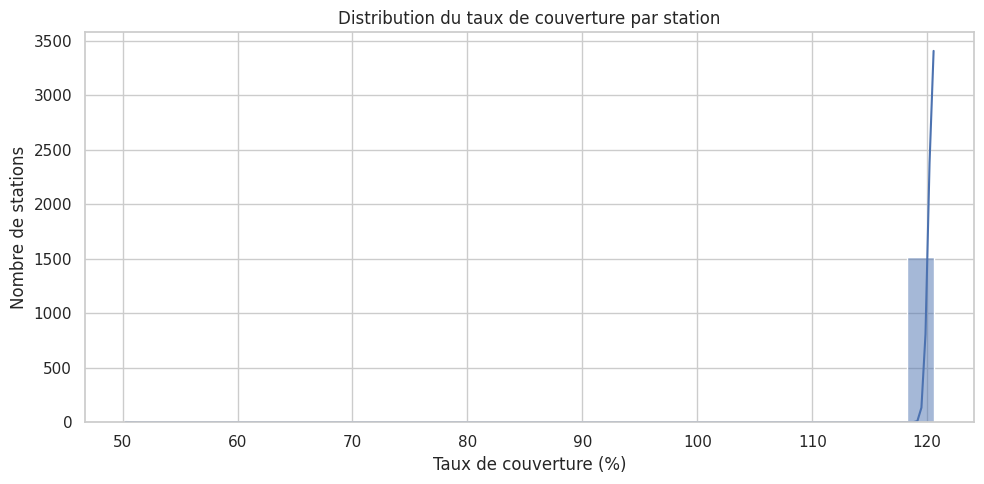

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    couverture_stations["taux_couverture_pct"],
    bins=30,
    kde=True
)

plt.title("Distribution du taux de couverture par station")
plt.xlabel("Taux de couverture (%)")
plt.ylabel("Nombre de stations")
plt.tight_layout()
plt.show()

In [13]:
couverture_stations.sort_values(
    "taux_couverture_pct",
    ascending=True
).head(20).round(2)

,nb_creneaux,premiere_observation,derniere_observation,taux_couverture_pct
station_id,,,,
27414460,724,2026-10-28 11:25:00+01:00,2026-10-30 23:55:00+01:00,50.280
94250567,1736,2026-10-25 00:00:00+02:00,2026-10-30 23:55:00+01:00,120.560
94555589,1736,2026-10-25 00:00:00+02:00,2026-10-30 23:55:00+01:00,120.560
95073815,1736,2026-10-25 00:00:00+02:00,2026-10-30 23:55:00+01:00,120.560
95845524,1736,2026-10-25 00:00:00+02:00,2026-10-30 23:55:00+01:00,120.560
95927849,1736,2026-10-25 00:00:00+02:00,2026-10-30 23:55:00+01:00,120.560
963786819,1736,2026-10-25 00:00:00+02:00,2026-10-30 23:55:00+01:00,120.560
96512532,1736,2026-10-25 00:00:00+02:00,2026-10-30 23:55:00+01:00,120.560
96608796,1736,2026-10-25 00:00:00+02:00,2026-10-30 23:55:00+01:00,120.560


### Synthèse de la préparation initiale

À l'issue de cette étape, les données ont été chargées, normalisées et examinées afin de vérifier leur qualité et leur couverture temporelle.

La période d'étude retenue s'étend du 25 au 30 octobre 2026. Les éventuelles anomalies et insuffisances de couverture identifiées seront prises en compte dans les étapes suivantes.

Le jeu de données est désormais prêt pour la définition du problème de classification et la construction de la variable cible, sous réserve des traitements nécessaires identifiés lors des audits précédents.

In [14]:
print("Dimensions du dataset :", df.shape)
print("Nombre de stations :", df["station_id"].nunique())
print("Nombre de journées :", df["jour"].nunique())
print("Période :", df["jour"].min(), "au", df["jour"].max())

print(
    "Nombre de doublons station-créneau :",
    df.duplicated(["station_id", "temps"]).sum()
)

Dimensions du dataset : (2637708, 12)
Nombre de stations : 1520
Nombre de journées : 6
Période : 2026-10-25 au 2026-10-30
Nombre de doublons station-créneau : 0


In [15]:
# Nombre de créneaux distincts observés sur l'ensemble du réseau

NB_CRENEAUX_OBSERVES = df["temps"].nunique()

# Couverture par station

couverture_stations = (
    df.groupby("station_id")
    .agg(
        nb_creneaux=("temps", "nunique"),
        premiere_observation=("temps", "min"),
        derniere_observation=("temps", "max")
    )
)

couverture_stations["taux_couverture_pct"] = (
    couverture_stations["nb_creneaux"]
    / NB_CRENEAUX_OBSERVES * 100
)

print("Nombre de créneaux observés :", NB_CRENEAUX_OBSERVES)

couverture_stations["taux_couverture_pct"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).round(2)

Nombre de créneaux observés : 1736


,taux_couverture_pct
count,1520.000
mean,99.960
std,1.500
min,41.710
1%,100.000
5%,100.000
25%,100.000
50%,100.000
75%,100.000
95%,100.000


In [16]:
# Examiner les observations de la station la moins couverte

station_atypique = "27414460"

df[df["station_id"] == station_atypique].sort_values(
    "collecte"
).head()

,station_id,collecte,velos,velos_meca,velos_elec,bornes_libres,en_service,is_installed,is_returning,last_reported,temps,jour
1537793,27414460,2026-10-28 10:25:33+00:00,32,13.000,19.000,0,0,1,0,1793183057,2026-10-28 11:25:00+01:00,2026-10-28
1539313,27414460,2026-10-28 10:30:58+00:00,32,13.000,19.000,0,0,1,0,1793183057,2026-10-28 11:30:00+01:00,2026-10-28
1540831,27414460,2026-10-28 10:35:35+00:00,32,13.000,19.000,0,0,1,0,1793183057,2026-10-28 11:35:00+01:00,2026-10-28
1542352,27414460,2026-10-28 10:40:42+00:00,32,13.000,19.000,0,0,1,0,1793183057,2026-10-28 11:40:00+01:00,2026-10-28
1543873,27414460,2026-10-28 10:45:47+00:00,32,13.000,19.000,0,0,1,0,1793183057,2026-10-28 11:45:00+01:00,2026-10-28


In [17]:
# Examiner quelques observations où les types de vélos sont manquants

df.loc[
    df["velos_meca"].isna() | df["velos_elec"].isna(),
    [
        "station_id",
        "collecte",
        "velos",
        "velos_meca",
        "velos_elec",
        "bornes_libres"
    ]
].head(10)

,station_id,collecte,velos,velos_meca,velos_elec,bornes_libres
4557,1063044618,2026-10-24 22:15:35+00:00,22,NaN,NaN,7
4558,11908510683,2026-10-24 22:15:35+00:00,26,NaN,NaN,0
4559,1063421211,2026-10-24 22:15:35+00:00,39,NaN,NaN,0
4560,11908496227,2026-10-24 22:15:35+00:00,1,NaN,NaN,23
4561,1074333296,2026-10-24 22:15:35+00:00,17,NaN,NaN,24
4562,54000537,2026-10-24 22:15:35+00:00,9,NaN,NaN,6
4563,98132679,2026-10-24 22:15:35+00:00,2,NaN,NaN,47
4564,48800374,2026-10-24 22:15:35+00:00,0,NaN,NaN,14
4565,80298493,2026-10-24 22:15:35+00:00,25,NaN,NaN,0
4566,1063971944,2026-10-24 22:15:35+00:00,0,NaN,NaN,29


In [18]:
# Vérification des valeurs manquantes sur la période retenue
df[["velos", "velos_meca", "velos_elec"]].isna().sum().to_frame(
    name="nb_manquants"
).assign(
    taux_pct=lambda x: (x["nb_manquants"] / len(df) * 100).round(2)
)

,nb_manquants,taux_pct
velos,0,0.000
velos_meca,27350,1.040
velos_elec,27350,1.040


### Conclusion - Etape 2 :

Après le chargement, le filtrage temporel et les vérifications de qualité, le jeu de données retenu couvre la période du 25 au 30 octobre 2026.

Il contient **2 637 708 observations réparties sur 1 520 stations** et **1 736 créneaux temporels observés**.

Les contrôles effectués montrent :
- Une couverture complète pour 1 519 stations sur 1 520.
- Une station présentant un historique plus court, conservée à ce stade.
- Aucune observation dupliquée ni incohérence détectée dans les contrôles réalisés.
- Des valeurs manquantes uniquement dans les variables détaillant les vélos mécaniques et électriques. Le nombre total de vélos disponibles reste renseigné.

Les données sont désormais prêtes pour la construction de la variable cible et des variables explicatives. Les traitements spécifiques nécessaires seront réalisés au cours des étapes suivantes, en évitant toute suppression ou imputation injustifiée.

## 3. Définition de la variable cible

L'objectif de cette étape est de construire une variable cible binaire permettant de prédire si une station Vélib' deviendra vide au cours des 30 prochaines minutes.

Pour chaque station et chaque instant de collecte, nous chercherons à déterminer si le nombre de vélos disponibles atteint zéro au moins une fois pendant les 30 minutes suivantes.

Cette étape nécessite de prendre en compte l'ordre chronologique des observations, de vérifier la disponibilité des relevés futurs et d'éviter toute fuite de données.

### Définition de la cible

La variable cible `target` est définie selon les règles suivantes :

- **1 :** la station atteint zéro vélo disponible au moins une fois dans les 30 minutes suivant l'instant de prédiction.
- **0 :** la station ne devient pas vide pendant cet horizon.
- **Observation exclue :** la station est déjà vide à l'instant de prédiction ou les observations futures nécessaires sont indisponibles.

L'instant de prédiction correspond à l'instant courant \(t\), et l'horizon de prédiction couvre l'intervalle suivant :
(t, t + 30 minutes)

La cible sera construite indépendamment pour chaque station, en respectant strictement la chronologie des relevés.

In [19]:
# Vérification des intervalles entre observations pour chaque station

df_trie = df.sort_values(["station_id", "collecte"]).copy()

df_trie["intervalle_min"] = (
    df_trie.groupby("station_id")["collecte"]
    .diff()
    .dt.total_seconds() / 60
)

df_trie["intervalle_min"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
).round(2)

,intervalle_min
count,2636188.000
mean,5.010
std,0.410
min,3.120
50%,5.000
90%,5.450
95%,5.580
99%,5.780
max,10.420


Cette vérification permet d'étudier les intervalles temporels entre deux observations successives d'une même station. Elle permet notamment d'identifier les éventuelles interruptions de collecte qui pourraient empêcher la construction fiable de la variable cible sur un horizon de 30 minutes.

### Analyse des interruptions de collecte

Afin de construire une variable cible fiable, nous analysons les interruptions de collecte pour chaque station.

Un intervalle supérieur à 5 minutes indique qu'au moins un relevé intermédiaire attendu est absent. Ces interruptions doivent être prises en compte pour éviter de considérer à tort une station comme n'étant jamais devenue vide pendant l'horizon de prédiction.

In [20]:
# Analyse des intervalles supérieurs à 5 minutes

intervalles_anormaux = df_trie[
    df_trie["intervalle_min"] > 5.5
]

print("Nombre d'intervalles > 5,5 min :", len(intervalles_anormaux))
print(
    "Nombre de stations concernées :",
    intervalles_anormaux["station_id"].nunique()
)

print("\nRépartition des intervalles :")
print(
    intervalles_anormaux["intervalle_min"]
    .describe()
    .round(2)
)

Nombre d'intervalles > 5,5 min : 220317
Nombre de stations concernées : 1520

Répartition des intervalles :
count   220317.000
mean         5.780
std          0.730
min          5.520
25%          5.570
50%          5.600
75%          5.650
max         10.420
Name: intervalle_min, dtype: float64


### Vérification des créneaux manquants

Les observations étant alignées sur des créneaux de 5 minutes, nous utilisons la variable `temps` pour identifier les interruptions de collecte.

Un intervalle de 10 minutes ou plus entre deux observations successives d'une même station indique qu'au moins un créneau intermédiaire est absent.

Cette vérification permet d'évaluer la continuité temporelle des données avant la construction de la variable cible.

In [21]:
# Calcul des intervalles entre créneaux successifs par station

df_trie["intervalle_temps_min"] = (
    df_trie.groupby("station_id")["temps"]
    .diff()
    .dt.total_seconds() / 60
)

# Statistiques des intervalles
print(
    df_trie["intervalle_temps_min"]
    .describe()
    .round(2)
)

# Identification des véritables interruptions
intervalles_manquants = df_trie[
    df_trie["intervalle_temps_min"] > 5
]

print("\nNombre d'intervalles avec créneau manquant :",
      len(intervalles_manquants))

print("Nombre de stations concernées :",
      intervalles_manquants["station_id"].nunique())

print("Durée maximale d'interruption :",
      intervalles_manquants["intervalle_temps_min"].max())

count   2636188.000
mean          5.010
std           0.240
min           5.000
25%           5.000
50%           5.000
75%           5.000
max          10.000
Name: intervalle_temps_min, dtype: float64

Nombre d'intervalles avec créneau manquant : 6079
Nombre de stations concernées : 1520
Durée maximale d'interruption : 10.0


L'analyse temporelle montre que les observations sont principalement espacées de 5 minutes. Sur les 2 636 188 intervalles analysés, 6 079 présentent un espacement de 10 minutes, correspondant à un créneau intermédiaire manquant.

Ces interruptions restent limitées en proportion, mais doivent être prises en compte lors de la construction de la variable cible afin de ne pas attribuer une étiquette négative lorsqu'un événement a pu se produire pendant une période non observée.

### Construction de la variable cible

Pour chaque station et chaque instant de prédiction, nous examinons les six relevés suivants, correspondant aux horizons de 5, 10, 15, 20, 25 et 30 minutes.

La variable cible est attribuée selon les règles suivantes :

- `target = 1` : au moins un des six relevés indique zéro vélo disponible.
- `target = 0` : les six relevés sont disponibles et aucun n'indique zéro vélo.
- Observation exclue : un ou plusieurs relevés futurs sont manquants, ou la station est déjà vide à l'instant de prédiction.

La cible repose donc sur les états effectivement observés, sans supposer ce qui a pu se produire pendant une interruption de collecte.

In [22]:
# Préparation des observations dans l'ordre chronologique
df_trie = df.sort_values(
    ["station_id", "temps"]
).copy()

# Regroupement des observations par station
groupes = df_trie.groupby("station_id", sort=False)

# Vérification de la disponibilité des 6 relevés futurs
fenetre_complete = pd.Series(
    True,
    index=df_trie.index
)

# Détection d'un état vide dans les 30 prochaines minutes
vide_dans_30min = pd.Series(
    False,
    index=df_trie.index
)

for i in range(1, 7):
    temps_futur = groupes["temps"].shift(-i)
    velos_futurs = groupes["velos"].shift(-i)

    # Vérifier que le relevé correspond exactement au créneau attendu
    fenetre_complete &= (
        temps_futur == df_trie["temps"] + pd.Timedelta(minutes=5 * i)
    )

    # Vérifier si la station devient vide
    vide_dans_30min |= velos_futurs.eq(0)

# Exclure les observations déjà vides et celles sans horizon complet
masque_valide = (
    df_trie["velos"].gt(0) &
    fenetre_complete
)

# Création du nouveau jeu de données
df_cible = df_trie.loc[masque_valide].copy()

# Attribution de la cible binaire
df_cible["target"] = (
    vide_dans_30min.loc[masque_valide].astype("int8")
)

# Bilan de la construction
print("Nombre initial d'observations :", len(df_trie))

print(
    "Observations déjà vides :",
    df_trie["velos"].eq(0).sum()
)

print(
    "Horizons incomplets parmi les stations non vides :",
    (df_trie["velos"].gt(0) & ~fenetre_complete).sum()
)

print("Observations retenues :", len(df_cible))

print("\nRépartition de la cible :")
print(df_cible["target"].value_counts().sort_index())

print("\nRépartition en pourcentage :")
print(
    (df_cible["target"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Nombre initial d'observations : 2637708
Observations déjà vides : 165944
Horizons incomplets parmi les stations non vides : 42677
Observations retenues : 2429087

Répartition de la cible :
target
0    2357199
1      71888
Name: count, dtype: int64

Répartition en pourcentage :
target
0   97.040
1    2.960
Name: proportion, dtype: float64


La construction de la variable cible a permis de retenir 2 429 087 observations sur les 2 637 708 observations initiales.

Les observations ont été exclues dans deux situations :
- La station était déjà vide à l'instant de prédiction : 165 944 observations.
- L'horizon futur de 30 minutes était incomplet : 42 677 observations.

La variable cible présente un déséquilibre important :
- Classe 0 : 2 357 199 observations (97,04 %).
- Classe 1 : 71 888 observations (2,96 %).

Ce déséquilibre devra être pris en compte lors de l'entraînement et de l'évaluation des modèles de classification.

### Vérification de la cohérence cible


In [23]:
# Vérification de la cohérence de la cible

verification = pd.Series(
    False,
    index=df_cible.index
)

for i in range(1, 7):
    velos_futurs = (
        df_trie.groupby("station_id")["velos"]
        .shift(-i)
    )

    verification |= velos_futurs.loc[df_cible.index].eq(0)

print(
    "Nombre de labels positifs incorrects :",
    (df_cible["target"].eq(1) & ~verification).sum()
)

print(
    "Nombre de labels négatifs incorrects :",
    (df_cible["target"].eq(0) & verification).sum()
)

Nombre de labels positifs incorrects : 0
Nombre de labels négatifs incorrects : 0


# 4. Feature Engineering

L'objectif de cette étape est de créer des variables explicatives pertinentes à partir des données disponibles à l'instant de prédiction.

Nous allons notamment exploiter :
- Les caractéristiques temporelles : heure, jour de la semaine, week-end.
- L'état actuel de la station : vélos disponibles, bornes libres, état de fonctionnement.
- L'historique de disponibilité : évolution du nombre de vélos et tendances récentes.


### Variables temporelles

Les disponibilités des stations Vélib' peuvent varier selon l'heure de la journée, le jour de la semaine et les habitudes de déplacement.

Nous extrayons donc plusieurs caractéristiques temporelles à partir de l'instant de prédiction :
- L'heure de la journée.
- Le jour de la semaine.
- L'indicateur de week-end.
- Des représentations cycliques de l'heure pour tenir compte de la continuité entre 23h et 00h.

In [24]:
# Extraction des caractéristiques temporelles

df_cible["heure"] = df_cible["temps"].dt.hour
df_cible["jour_semaine"] = df_cible["temps"].dt.dayofweek
df_cible["weekend"] = (
    df_cible["jour_semaine"].isin([5, 6]).astype(int)
)

# Encodage cyclique de l'heure
df_cible["heure_sin"] = np.sin(
    2 * np.pi * df_cible["heure"] / 24
)

df_cible["heure_cos"] = np.cos(
    2 * np.pi * df_cible["heure"] / 24
)

# Vérification
df_cible[
    ["temps", "heure", "jour_semaine", "weekend",
     "heure_sin", "heure_cos"]
].head()

,temps,heure,jour_semaine,weekend,heure_sin,heure_cos
1506,2026-10-25 00:00:00+02:00,0,6,1,0.000,1.000
3026,2026-10-25 00:05:00+02:00,0,6,1,0.000,1.000
4543,2026-10-25 00:10:00+02:00,0,6,1,0.000,1.000
6062,2026-10-25 00:15:00+02:00,0,6,1,0.000,1.000
7581,2026-10-25 00:20:00+02:00,0,6,1,0.000,1.000


Les caractéristiques temporelles ont été extraites avec succès. L'heure est également représentée par deux variables cycliques (`heure_sin` et `heure_cos`) afin de préserver la continuité entre les heures de la journée.

### Variables liées à l'état actuel de la station

L'état courant d'une station constitue une information essentielle pour anticiper son passage à vide.

Nous construisons des variables décrivant le niveau de disponibilité des vélos et des bornes à l'instant de prédiction, ainsi que la proportion de vélos disponibles par rapport à la capacité totale de la station.

In [25]:
# Variables décrivant l'état actuel de la station

df_cible["capacite_totale"] = (
    df_cible["velos"] + df_cible["bornes_libres"]
)

df_cible["taux_disponibilite"] = (
    df_cible["velos"] / df_cible["capacite_totale"].replace(0, np.nan)
)

# Vérification
df_cible[
    ["velos", "bornes_libres", "capacite_totale",
     "taux_disponibilite", "en_service"]
].describe().round(3)

,velos,bornes_libres,capacite_totale,taux_disponibilite,en_service
count,2429087.000,2429087.000,2429087.000,2429087.000,2429087.000
mean,13.115,18.519,31.634,0.416,0.984
std,11.508,12.498,12.188,0.299,0.127
min,1.000,0.000,4.000,0.013,0.000
25%,4.000,9.000,23.000,0.150,1.000
50%,10.000,17.000,29.000,0.353,1.000
75%,19.000,26.000,38.000,0.653,1.000
max,82.000,97.000,100.000,1.000,1.000


Les variables décrivant l'état actuel des stations ont été construites avec succès. Elles permettent de caractériser le nombre de vélos disponibles, les bornes libres, la capacité totale estimée et le taux de disponibilité.

Aucune valeur manquante n'a été détectée dans ces variables. Elles seront conservées pour les étapes suivantes de modélisation.

### Variables historiques de disponibilité

L'évolution du nombre de vélos disponibles au cours des minutes précédentes peut fournir des informations utiles pour anticiper le passage d'une station à vide.

Nous créons des variables historiques représentant le nombre de vélos disponibles 5, 10 et 15 minutes avant l'instant de prédiction.

Les valeurs historiques sont calculées séparément pour chaque station. Lorsqu'un relevé historique attendu est absent, la valeur correspondante est laissée manquante afin de ne pas utiliser un relevé plus ancien comme s'il était récent.

In [26]:
# Création des variables historiques

groupes_hist = df_trie.groupby("station_id", sort=False)

for lag in [1, 2, 3]:

    minutes = lag * 5

    temps_precedent = groupes_hist["temps"].shift(lag)
    velos_precedents = groupes_hist["velos"].shift(lag)

    # Vérifier que le relevé correspond exactement à l'horizon attendu
    condition = (
        temps_precedent ==
        df_trie["temps"] - pd.Timedelta(minutes=minutes)
    )

    df_trie[f"velos_moins_{minutes}min"] = (
        velos_precedents.where(condition)
    )

    # Reporter les variables sur le jeu de données de modélisation
    df_cible[f"velos_moins_{minutes}min"] = (
        df_trie.loc[df_cible.index, f"velos_moins_{minutes}min"]
    )

# Vérification
df_cible[
    [
        "station_id",
        "temps",
        "velos",
        "velos_moins_5min",
        "velos_moins_10min",
        "velos_moins_15min"
    ]
].head(10)

,station_id,temps,velos,velos_moins_5min,velos_moins_10min,velos_moins_15min
1506,1002059045,2026-10-25 00:00:00+02:00,15,NaN,NaN,NaN
3026,1002059045,2026-10-25 00:05:00+02:00,15,15.000,NaN,NaN
4543,1002059045,2026-10-25 00:10:00+02:00,15,15.000,15.000,NaN
6062,1002059045,2026-10-25 00:15:00+02:00,15,15.000,15.000,15.000
7581,1002059045,2026-10-25 00:20:00+02:00,15,15.000,15.000,15.000
9101,1002059045,2026-10-25 00:25:00+02:00,15,15.000,15.000,15.000
10620,1002059045,2026-10-25 00:30:00+02:00,15,15.000,15.000,15.000
12139,1002059045,2026-10-25 00:35:00+02:00,15,15.000,15.000,15.000
13657,1002059045,2026-10-25 00:40:00+02:00,15,15.000,15.000,15.000
15177,1002059045,2026-10-25 00:45:00+02:00,15,15.000,15.000,15.000



Une vérification des variables historiques est effectuée afin de mesurer la proportion de valeurs manquantes. Celles-ci peuvent notamment provenir du début de la période d'observation ou des interruptions de collecte identifiées précédemment.

### Vérification du taux de valeurs manquantes

In [27]:
# Analyse des valeurs manquantes dans les variables historiques

colonnes_historiques = [
    "velos_moins_5min",
    "velos_moins_10min",
    "velos_moins_15min"
]

df_cible[colonnes_historiques].isna().sum().to_frame(
    name="nb_manquants"
).assign(
    taux_pct=lambda x: (
        x["nb_manquants"] / len(df_cible) * 100
    ).round(2)
)

,nb_manquants,taux_pct
velos_moins_5min,7099,0.290
velos_moins_10min,14209,0.580
velos_moins_15min,21310,0.880


### Variables d'évolution de la disponibilité

Au-delà du nombre de vélos disponibles à un instant donné, son évolution récente peut constituer un indicateur important du risque de passage à vide.

Nous calculons la variation du nombre de vélos disponibles entre l'instant actuel et les relevés effectués 5, 10 et 15 minutes auparavant.

Une variation négative indique une diminution du nombre de vélos disponibles, tandis qu'une variation positive traduit une augmentation.

In [28]:
# Calcul des variations du nombre de vélos disponibles

for minutes in [5, 10, 15]:
    df_cible[f"variation_velos_{minutes}min"] = (
        df_cible["velos"] -
        df_cible[f"velos_moins_{minutes}min"]
    )

# Vérification des nouvelles variables
df_cible[
    [
        "temps",
        "velos",
        "velos_moins_5min",
        "variation_velos_5min",
        "velos_moins_10min",
        "variation_velos_10min",
        "velos_moins_15min",
        "variation_velos_15min"
    ]
].head(10)

,temps,velos,velos_moins_5min,variation_velos_5min,velos_moins_10min,variation_velos_10min,velos_moins_15min,variation_velos_15min
1506,2026-10-25 00:00:00+02:00,15,NaN,NaN,NaN,NaN,NaN,NaN
3026,2026-10-25 00:05:00+02:00,15,15.000,0.000,NaN,NaN,NaN,NaN
4543,2026-10-25 00:10:00+02:00,15,15.000,0.000,15.000,0.000,NaN,NaN
6062,2026-10-25 00:15:00+02:00,15,15.000,0.000,15.000,0.000,15.000,0.000
7581,2026-10-25 00:20:00+02:00,15,15.000,0.000,15.000,0.000,15.000,0.000
9101,2026-10-25 00:25:00+02:00,15,15.000,0.000,15.000,0.000,15.000,0.000
10620,2026-10-25 00:30:00+02:00,15,15.000,0.000,15.000,0.000,15.000,0.000
12139,2026-10-25 00:35:00+02:00,15,15.000,0.000,15.000,0.000,15.000,0.000
13657,2026-10-25 00:40:00+02:00,15,15.000,0.000,15.000,0.000,15.000,0.000
15177,2026-10-25 00:45:00+02:00,15,15.000,0.000,15.000,0.000,15.000,0.000


### Analyse des variables d'évolution

In [29]:
# Statistiques descriptives des variations

colonnes_variations = [
    "variation_velos_5min",
    "variation_velos_10min",
    "variation_velos_15min"
]

df_cible[colonnes_variations].describe().round(2)

,variation_velos_5min,variation_velos_10min,variation_velos_15min
count,2421988.000,2414878.000,2407777.000
mean,0.010,0.010,0.020
std,0.760,1.110,1.380
min,-23.000,-32.000,-44.000
25%,0.000,0.000,0.000
50%,0.000,0.000,0.000
75%,0.000,0.000,0.000
max,26.000,27.000,28.000


Les variables d'évolution de la disponibilité ont été construites pour des horizons de 5, 10 et 15 minutes.

Les statistiques montrent que les variations sont généralement faibles, avec une médiane égale à zéro pour les trois horizons. Leur dispersion augmente avec la durée considérée, ce qui permet de caractériser les évolutions récentes de la disponibilité des stations.

Ces variables sont conservées pour la modélisation, sans traitement particulier des valeurs extrêmes à ce stade.

### Variables de tendance historique

Afin de caractériser les tendances récentes de disponibilité, nous calculons des moyennes historiques du nombre de vélos disponibles sur les trois et six relevés précédant l'instant de prédiction.

Ces indicateurs permettent de distinguer les stations dont la disponibilité diminue progressivement de celles dont le nombre de vélos reste relativement stable.

Les calculs utilisent exclusivement les observations passées afin d'éviter toute fuite de données.

In [42]:
# Calcul des décalages historiques supplémentaires : 20, 25 et 30 minutes

for minutes in [20, 25, 30]:
    decalage = minutes // 5

    temps_precedent = groupes_hist["temps"].shift(decalage)
    velos_precedents = groupes_hist["velos"].shift(decalage)

    condition = (
        temps_precedent == df_trie["temps"] - pd.Timedelta(minutes=minutes)
    )

    df_trie[f"velos_moins_{minutes}min"] = velos_precedents.where(condition)

    df_cible[f"velos_moins_{minutes}min"] = (
        df_trie.loc[df_cible.index, f"velos_moins_{minutes}min"]
    )

In [43]:
# Moyenne des trois relevés précédant l'instant de prédiction

colonnes_historique_3 = [
    "velos_moins_5min",
    "velos_moins_10min",
    "velos_moins_15min"
]

df_cible["moyenne_velos_3_releves"] = (
    df_cible[colonnes_historique_3].mean(axis=1)
)

# Conserver NaN si au moins un relevé historique est manquant
df_cible.loc[
    df_cible[colonnes_historique_3].isna().any(axis=1),
    "moyenne_velos_3_releves"
] = np.nan

In [44]:
# Moyenne des six relevés précédant l'instant de prédiction

colonnes_historique = [
    "velos_moins_5min",
    "velos_moins_10min",
    "velos_moins_15min",
    "velos_moins_20min",
    "velos_moins_25min",
    "velos_moins_30min"
]

df_cible["moyenne_velos_6_releves"] = (
    df_cible[colonnes_historique].mean(axis=1)
)

# Conserver NaN si au moins un relevé historique est manquant
df_cible.loc[
    df_cible[colonnes_historique].isna().any(axis=1),
    "moyenne_velos_6_releves"
] = np.nan

In [45]:
df_cible[
    [
        "station_id",
        "temps",
        "velos",
        "moyenne_velos_3_releves",
        "moyenne_velos_6_releves"
    ]
].head(12)

,station_id,temps,velos,moyenne_velos_3_releves,moyenne_velos_6_releves
1506,1002059045,2026-10-25 00:00:00+02:00,15,NaN,NaN
3026,1002059045,2026-10-25 00:05:00+02:00,15,NaN,NaN
4543,1002059045,2026-10-25 00:10:00+02:00,15,NaN,NaN
6062,1002059045,2026-10-25 00:15:00+02:00,15,15.000,NaN
7581,1002059045,2026-10-25 00:20:00+02:00,15,15.000,NaN
9101,1002059045,2026-10-25 00:25:00+02:00,15,15.000,NaN
10620,1002059045,2026-10-25 00:30:00+02:00,15,15.000,15.000
12139,1002059045,2026-10-25 00:35:00+02:00,15,15.000,15.000
13657,1002059045,2026-10-25 00:40:00+02:00,15,15.000,15.000
15177,1002059045,2026-10-25 00:45:00+02:00,15,15.000,15.000


### Vérification des variables historiques et de tendance

Cette étape permet de contrôler la proportion de valeurs manquantes introduites par la création des variables historiques. Ces valeurs correspondent principalement aux observations pour lesquelles l'historique nécessaire n'est pas disponible ou présente des interruptions temporelles.

In [46]:
colonnes_historiques = [
    "velos_moins_5min",
    "velos_moins_10min",
    "velos_moins_15min",
    "velos_moins_20min",
    "velos_moins_25min",
    "velos_moins_30min",
    "moyenne_velos_3_releves",
    "moyenne_velos_6_releves"
]

taux_manquants = (
    df_cible[colonnes_historiques]
    .isna()
    .mean()
    .mul(100)
    .round(2)
)

print("Pourcentage de valeurs manquantes :")
display(taux_manquants.to_frame(name="Taux de valeurs manquantes (%)"))

Pourcentage de valeurs manquantes :


,Taux de valeurs manquantes (%)
velos_moins_5min,0.290
velos_moins_10min,0.580
velos_moins_15min,0.880
velos_moins_20min,1.170
velos_moins_25min,1.460
velos_moins_30min,1.750
moyenne_velos_3_releves,0.880
moyenne_velos_6_releves,1.750


## Conclusion - Etape 4

Le Feature Engineering a permis de créer plusieurs catégories de variables à partir des données initiales :

- **Variables temporelles :** heure, jour de la semaine, indicateur de week-end et encodage cyclique de l'heure.
- **Variables liées à l'état courant :** capacité totale estimée et taux de disponibilité.
- **Variables historiques :** nombre de vélos disponibles 5, 10, 15, 20, 25 et 30 minutes auparavant.
- **Variables d'évolution :** variations du nombre de vélos sur les 5, 10 et 15 dernières minutes.
- **Variables de tendance :** moyennes historiques sur les 3 et 6 relevés précédents.

Les variables historiques utilisent exclusivement des observations antérieures à l'instant de prédiction. Les valeurs manquantes sont conservées afin d'être traitées ultérieurement dans le pipeline de prétraitement.

Ces nouvelles variables constituent une première représentation de la dynamique de disponibilité des stations et serviront de base à l'analyse et à la sélection des variables.

# 5. Analyse des variables et sélection des features

### Analyse de la variable cible

Avant d'étudier les relations entre les variables explicatives et la cible, nous examinons la répartition des deux classes de prédiction :

- `target = 0` : la station ne devient pas vide dans les 30 prochaines minutes.
- `target = 1` : la station devient vide au moins une fois dans les 30 prochaines minutes.

Cette analyse permet de mesurer le déséquilibre des classes, qui devra être pris en compte lors de l'entraînement et de l'évaluation des modèles.

In [47]:
# Répartition des classes de la variable cible

repartition_cible = (
    df_cible["target"]
    .value_counts()
    .sort_index()
    .to_frame(name="Effectif")
)

repartition_cible["Pourcentage (%)"] = (
    df_cible["target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

display(repartition_cible)

,Effectif,Pourcentage (%)
target,,
0,2357199,97.040
1,71888,2.960


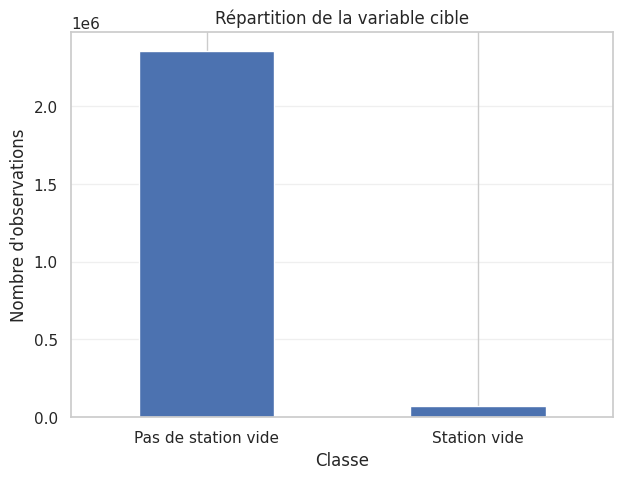

In [48]:
# Visualisation de la répartition de la cible

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

df_cible["target"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.title("Répartition de la variable cible")
plt.xlabel("Classe")
plt.ylabel("Nombre d'observations")
plt.xticks([0, 1], ["Pas de station vide", "Station vide"])
plt.grid(axis="y", alpha=0.3)
plt.show()

La variable cible présente un déséquilibre marqué entre les deux classes : 97,04 % des observations appartiennent à la classe 0, contre seulement 2,96 % pour la classe 1.

Ce déséquilibre signifie qu'un modèle peut obtenir une accuracy élevée sans détecter correctement les stations qui deviennent vides.

L'évaluation des modèles devra donc s'appuyer principalement sur des métriques adaptées aux classes déséquilibrées, notamment la précision, le rappel, le F1-score et l'Average Precision (PR-AUC).

### Analyse descriptive des variables numériques

Nous examinons les statistiques descriptives des variables numériques afin de mieux comprendre leur distribution, leur dispersion et leurs éventuelles valeurs extrêmes.

Cette première analyse permettra de repérer les variables peu variables ou présentant des distributions particulières avant d'étudier leur relation avec la cible.

In [49]:
# Statistiques descriptives des variables numériques

colonnes_numeriques = df_cible.select_dtypes(
    include=["number"]
).columns.drop("target")

display(
    df_cible[colonnes_numeriques]
    .describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
velos,2429087.000,13.120,11.510,1.000,4.000,10.000,19.000,82.000
velos_meca,2404940.000,8.000,9.630,0.000,1.000,4.000,12.000,71.000
velos_elec,2404940.000,5.110,5.250,0.000,1.000,3.000,7.000,72.000
bornes_libres,2429087.000,18.520,12.500,0.000,9.000,17.000,26.000,97.000
en_service,2429087.000,0.980,0.130,0.000,1.000,1.000,1.000,1.000
is_installed,2429087.000,1.000,0.000,1.000,1.000,1.000,1.000,1.000
is_returning,2429087.000,0.980,0.130,0.000,1.000,1.000,1.000,1.000
last_reported,2429087.000,1793003955.100,5031176.780,1511790036.000,1793006272.000,1793136151.000,1793265920.000,1793395843.000
heure,2429087.000,11.340,6.980,0.000,5.000,11.000,17.000,23.000
jour_semaine,2429087.000,2.670,1.980,0.000,1.000,2.000,4.000,6.000


### Analyse des variables selon la cible

Afin d'évaluer la pertinence des variables explicatives, nous comparons leurs statistiques selon les deux classes de la variable cible.

Cette analyse permet d'identifier les différences de comportement entre les stations qui deviennent vides dans les 30 prochaines minutes et celles qui ne le deviennent pas.

Nous examinons notamment les niveaux de disponibilité, les évolutions récentes et les caractéristiques temporelles.

In [50]:
# Comparaison des principales variables selon la cible

variables_analyse = [
    "velos",
    "bornes_libres",
    "taux_disponibilite",
    "variation_velos_5min",
    "variation_velos_10min",
    "variation_velos_15min",
    "moyenne_velos_3_releves",
    "moyenne_velos_6_releves"
]

comparaison_cible = (
    df_cible.groupby("target")[variables_analyse]
    .agg(["mean", "median"])
    .T
)

display(comparaison_cible.round(2))

target                              0      1
velos                   mean   13.460  1.700
                        median 10.000  1.000
bornes_libres           mean   18.260 27.050
                        median 17.000 25.000
taux_disponibilite      mean    0.430  0.070
                        median  0.370  0.050
variation_velos_5min    mean    0.010 -0.050
                        median  0.000  0.000
variation_velos_10min   mean    0.020 -0.090
                        median  0.000  0.000
variation_velos_15min   mean    0.030 -0.150
                        median  0.000  0.000
moyenne_velos_3_releves mean   13.450  1.800
                        median 10.330  1.330
moyenne_velos_6_releves mean   13.440  1.890
                        median 10.330  1.330

### Risque de passage à vide selon la disponibilité actuelle

Nous étudions la proportion d'observations associées à un passage à vide dans les 30 prochaines minutes, en fonction du nombre de vélos disponibles à l'instant de prédiction.

Cette analyse permet d'évaluer comment le risque évolue lorsque le nombre de vélos disponibles diminue.

In [51]:
# Regroupement des observations selon le nombre de vélos disponibles

bins = [0, 1, 2, 3, 5, 10, 20, float("inf")]
labels = ["1", "2", "3", "4-5", "6-10", "11-20", "21 et plus"]

df_analyse = df_cible.copy()

df_analyse["groupe_velos"] = pd.cut(
    df_analyse["velos"],
    bins=bins,
    labels=labels
)

risque_velos = (
    df_analyse.groupby("groupe_velos", observed=False)
    .agg(
        effectif=("target", "size"),
        passages_a_vide=("target", "sum"),
        taux_passage_vide=("target", "mean")
    )
)

risque_velos["taux_passage_vide_pct"] = (
    risque_velos["taux_passage_vide"] * 100
).round(2)

display(risque_velos.drop(columns="taux_passage_vide").round(2))

,effectif,passages_a_vide,taux_passage_vide_pct
groupe_velos,,,
1,174784,43744,25.030
2,169044,16740,9.900
3,157761,6411,4.060
4-5,269749,3818,1.420
6-10,491767,1030,0.210
11-20,650866,121,0.020
21 et plus,515116,24,0.000


Les résultats mettent en évidence une relation très nette entre le nombre de vélos disponibles à l'instant de prédiction et le risque de passage à vide dans les 30 minutes suivantes.

Lorsque la station ne dispose que d'un seul vélo, le risque atteint 25,03 %. Il diminue rapidement avec l'augmentation du nombre de vélos disponibles, jusqu'à devenir très faible au-delà de 10 vélos.

Cette variable semble donc particulièrement informative pour la prédiction. Elle devra être conservée parmi les variables candidates pour l'entraînement des modèles.

Cependant, le nombre de vélos disponibles ne suffit pas à lui seul à expliquer tous les passages à vide. D'autres variables, notamment les évolutions historiques et les caractéristiques temporelles, pourront apporter des informations complémentaires.

### Analyse des variables binaires et constantes

In [52]:
# Analyse des variables binaires

variables_binaires = [
    "en_service",
    "is_installed",
    "is_returning"
]

for variable in variables_binaires:
    print(f"\nRépartition de {variable} :")
    display(
        df_cible[variable]
        .value_counts(dropna=False)
        .to_frame("effectif")
        .assign(
            pourcentage=lambda x: (
                x["effectif"] / len(df_cible) * 100
            ).round(2)
        )
    )

# Vérification de l'identité entre les deux variables
print(
    "\nNombre de différences entre en_service et is_returning :",
    (df_cible["en_service"] != df_cible["is_returning"]).sum()
)


Répartition de en_service :


,effectif,pourcentage
en_service,,
1,2389156,98.360
0,39931,1.640



Répartition de is_installed :


,effectif,pourcentage
is_installed,,
1,2429087,100.000



Répartition de is_returning :


,effectif,pourcentage
is_returning,,
1,2389156,98.360
0,39931,1.640



Nombre de différences entre en_service et is_returning : 0


L'analyse des variables binaires révèle que `is_installed` est constante et ne présente donc aucun intérêt pour la modélisation. Elle sera supprimée.

Les variables `en_service` et `is_returning` présentent exactement les mêmes valeurs sur l'ensemble des observations. Afin d'éviter une redondance, une seule sera conservée : `en_service`.

Bien que cette variable soit déséquilibrée (98,36 % de valeurs à 1), elle est conservée provisoirement pour évaluer son apport aux modèles.

### Analyse des variables catégorielles et identifiants

In [53]:
# Analyse de la répartition des observations par station

nb_stations = df_cible["station_id"].nunique()
observations_station = df_cible["station_id"].value_counts()

print("Nombre de stations :", nb_stations)
print("\nNombre d'observations par station :")
display(observations_station.describe().to_frame("observations"))

Nombre de stations : 1504

Nombre d'observations par station :


,observations
count,1504.000
mean,1615.084
std,136.705
min,126.000
25%,1572.750
50%,1677.000
75%,1706.000
max,1706.000


L'analyse de `station_id` montre que les observations couvrent 1 504 stations, avec une répartition globalement équilibrée du nombre de relevés.

Cette variable constitue un identifiant et non une caractéristique directement exploitable comme mesure numérique. Elle ne sera donc pas intégrée aux variables explicatives dans un premier temps.

Elle sera toutefois conservée dans le DataFrame pour faciliter les analyses ultérieures par station et l'interprétation des résultats.

### Vérification des corrélations entre variables numériques

In [54]:
# Sélection des variables numériques pour l'analyse des corrélations

variables_corr = df_cible.select_dtypes(
    include=["number"]
).columns.drop([
    "target",
    "is_installed",
    "is_returning",
    "last_reported"
])

matrice_corr = df_cible[variables_corr].corr()

display(matrice_corr.round(2))

,velos,velos_meca,velos_elec,bornes_libres,en_service,heure,jour_semaine,weekend,heure_sin,heure_cos,capacite_totale,taux_disponibilite,velos_moins_5min,velos_moins_10min,velos_moins_15min,variation_velos_5min,variation_velos_10min,variation_velos_15min,moyenne_velos_3_releves,moyenne_velos_6_releves,velos_moins_20min,velos_moins_25min,velos_moins_30min
velos,1.000,0.890,0.560,-0.490,0.040,-0.030,-0.000,-0.010,0.030,-0.010,0.440,0.830,1.000,1.000,0.990,0.020,0.030,0.040,1.000,0.990,0.990,0.990,0.980
velos_meca,0.890,1.000,0.120,-0.390,0.030,-0.010,-0.000,-0.010,0.010,-0.010,0.450,0.690,0.890,0.890,0.890,0.000,0.010,0.010,0.890,0.890,0.890,0.890,0.890
velos_elec,0.560,0.120,1.000,-0.360,0.010,-0.040,-0.000,-0.010,0.050,0.000,0.160,0.550,0.550,0.550,0.550,0.040,0.060,0.080,0.550,0.540,0.540,0.540,0.530
bornes_libres,-0.490,-0.390,-0.360,1.000,-0.100,0.030,0.000,0.010,-0.030,-0.000,0.570,-0.780,-0.490,-0.480,-0.480,-0.020,-0.030,-0.040,-0.480,-0.480,-0.480,-0.480,-0.470
en_service,0.040,0.030,0.010,-0.100,1.000,0.000,-0.160,-0.200,0.000,-0.000,-0.070,0.050,0.040,0.040,0.040,0.000,0.000,0.000,0.040,0.040,0.040,0.040,0.030
heure,-0.030,-0.010,-0.040,0.030,0.000,1.000,-0.020,-0.010,-0.780,-0.110,0.000,-0.040,-0.030,-0.030,-0.030,0.010,0.010,0.010,-0.030,-0.030,-0.030,-0.030,-0.030
jour_semaine,-0.000,-0.000,-0.000,0.000,-0.160,-0.020,1.000,0.760,0.010,0.010,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000
weekend,-0.010,-0.010,-0.010,0.010,-0.200,-0.010,0.760,1.000,0.000,0.020,0.000,-0.010,-0.010,-0.010,-0.010,-0.000,-0.000,-0.000,-0.010,-0.010,-0.010,-0.010,-0.010
heure_sin,0.030,0.010,0.050,-0.030,0.000,-0.780,0.010,0.000,1.000,-0.010,-0.000,0.040,0.030,0.030,0.030,-0.010,-0.010,-0.010,0.030,0.030,0.030,0.030,0.030
heure_cos,-0.010,-0.010,0.000,-0.000,-0.000,-0.110,0.010,0.020,-0.010,1.000,-0.010,0.010,-0.010,-0.010,-0.010,0.010,0.010,0.010,-0.010,-0.010,-0.010,-0.010,-0.010


L'analyse des corrélations met en évidence plusieurs groupes de variables fortement liées.

Les variables décrivant le nombre de vélos disponibles à différents instants présentent des corrélations très élevées. Les variations historiques sont également corrélées entre elles. Enfin, certaines variables temporelles, comme `jour_semaine` et `weekend`, contiennent des informations partiellement redondantes.

Ces corrélations ne justifient pas à elles seules la suppression systématique des variables. Leur utilité dépendra notamment de l'algorithme utilisé.

Les variables candidates sont donc conservées à ce stade. Leur contribution sera évaluée lors de l'entraînement et de la comparaison des modèles.

### visualisation des corrélations

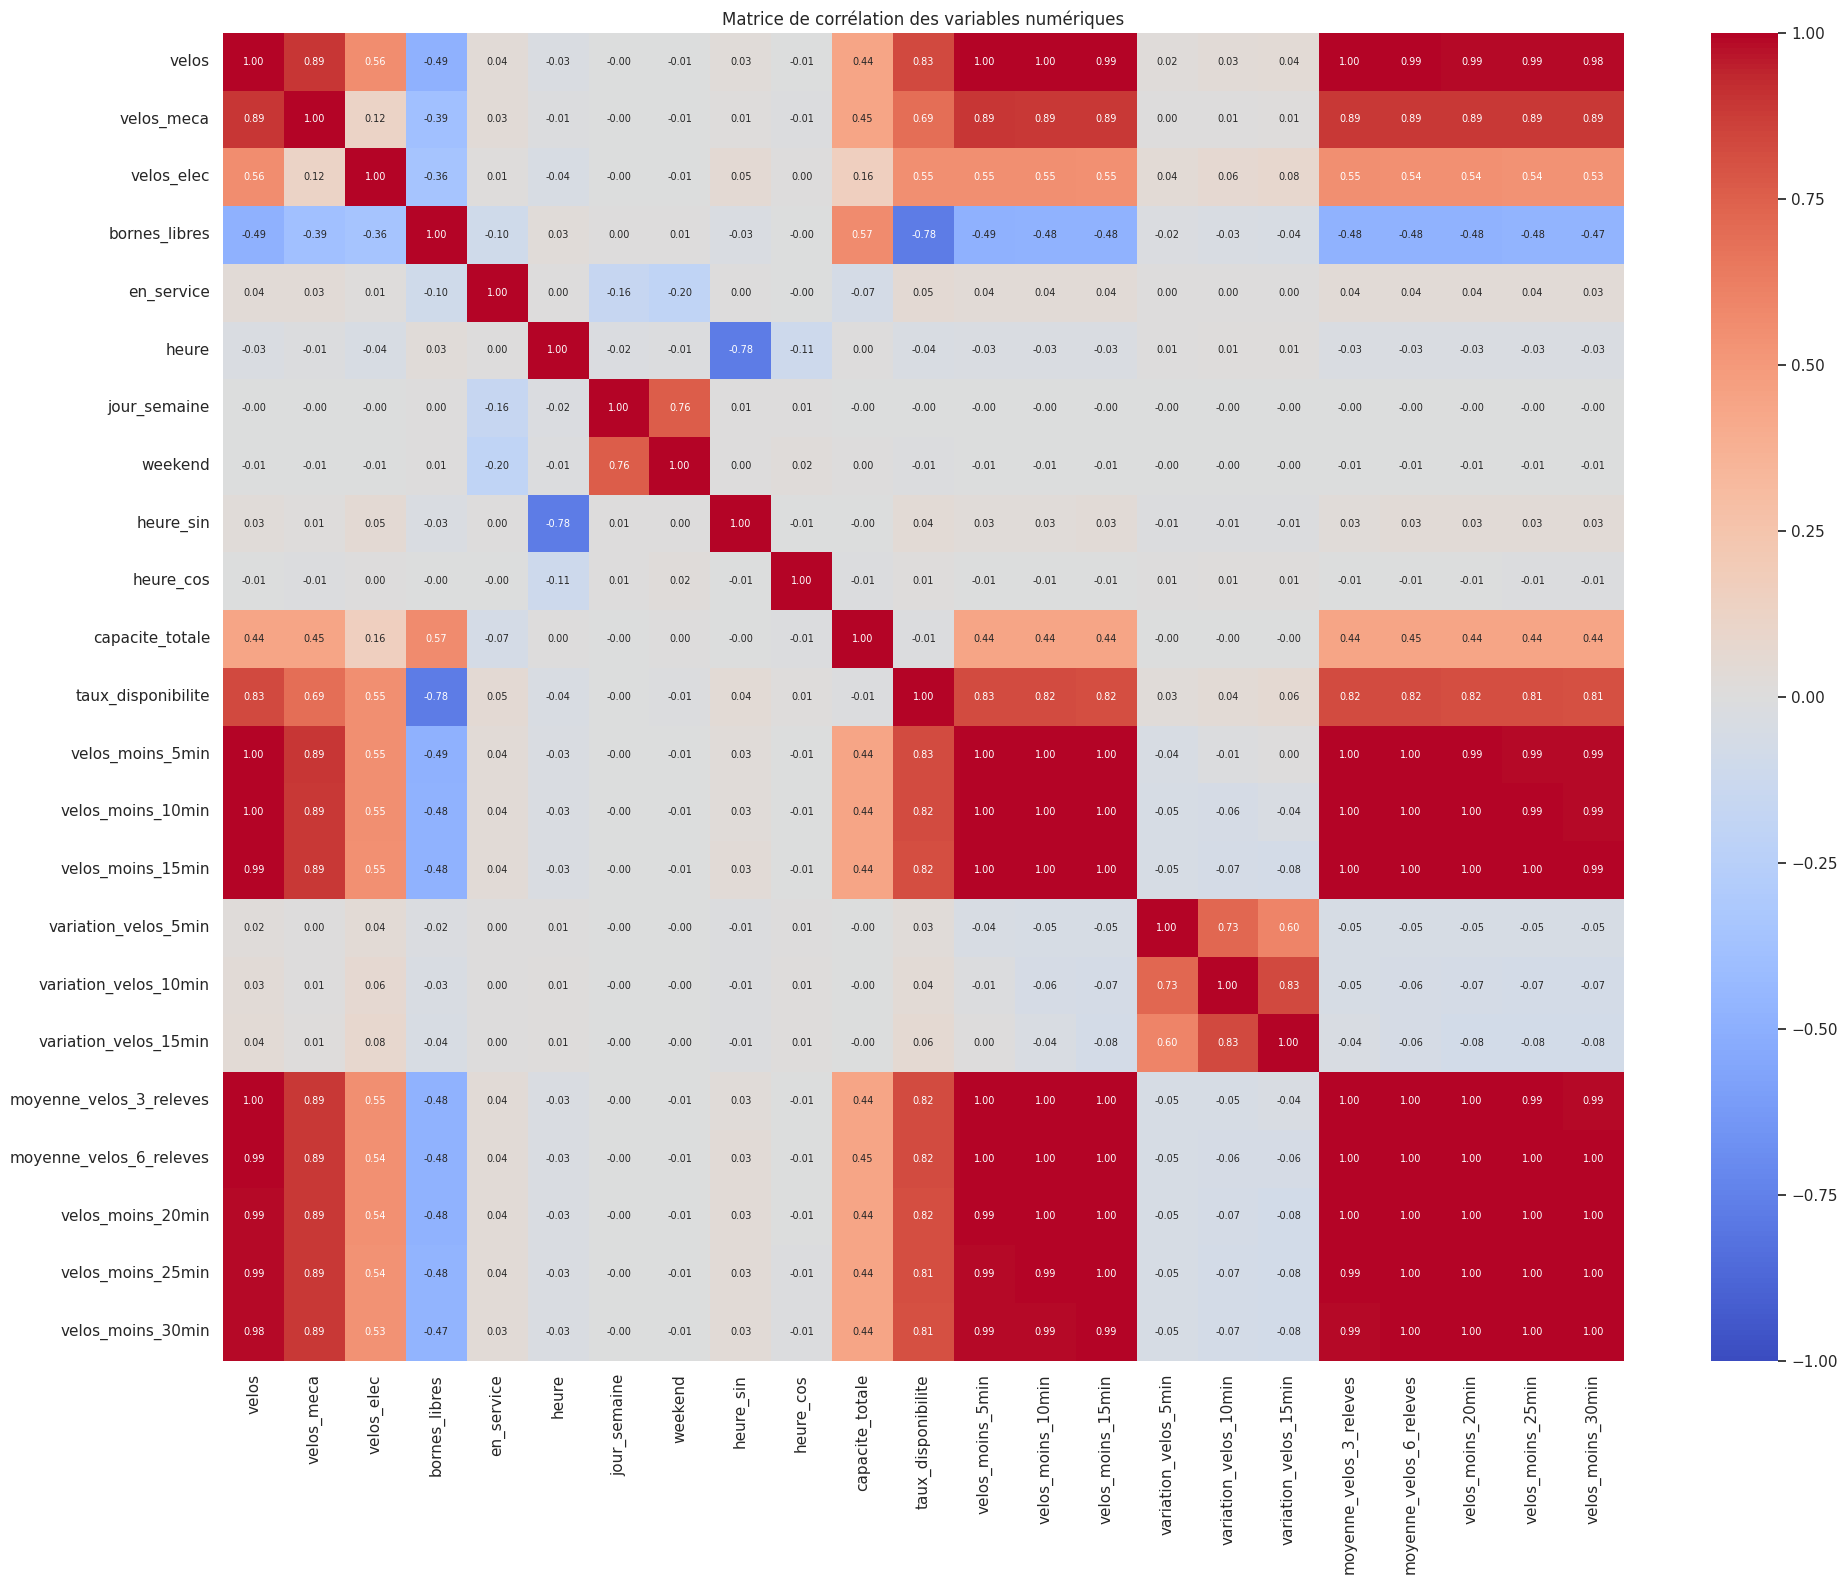

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(20, 16))

sns.heatmap(
    matrice_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7}
)

plt.title("Matrice de corrélation des variables numériques")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Sélection initiale des variables

In [56]:
# Définition des variables candidates pour la modélisation

colonnes_a_exclure = [
    "station_id",
    "collecte",
    "temps",
    "jour",
    "last_reported",
    "is_installed",
    "is_returning"
]

features = [
    colonne for colonne in df_cible.columns
    if colonne not in colonnes_a_exclure + ["target"]
]

X = df_cible[features].copy()
y = df_cible["target"].copy()

print("Nombre de variables explicatives :", len(features))
print("\nVariables retenues :")
print(features)

print("\nDimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Nombre de variables explicatives : 23

Variables retenues :
['velos', 'velos_meca', 'velos_elec', 'bornes_libres', 'en_service', 'heure', 'jour_semaine', 'weekend', 'heure_sin', 'heure_cos', 'capacite_totale', 'taux_disponibilite', 'velos_moins_5min', 'velos_moins_10min', 'velos_moins_15min', 'variation_velos_5min', 'variation_velos_10min', 'variation_velos_15min', 'moyenne_velos_3_releves', 'moyenne_velos_6_releves', 'velos_moins_20min', 'velos_moins_25min', 'velos_moins_30min']

Dimensions de X : (2429087, 23)
Dimensions de y : (2429087,)


In [57]:
# Vérification finale des variables explicatives

print("Types des variables :")
display(X.dtypes.to_frame("type"))

print("\nValeurs manquantes :")
manquants = X.isna().sum()

display(
    pd.DataFrame({
        "valeurs_manquantes": manquants,
        "pourcentage": (manquants / len(X) * 100).round(2)
    }).sort_values("pourcentage", ascending=False)
)

print("\nDimensions finales :", X.shape)

Types des variables :


,type
velos,int64
velos_meca,float64
velos_elec,float64
bornes_libres,int64
en_service,int64
heure,int32
jour_semaine,int32
weekend,int64
heure_sin,float64
heure_cos,float64



Valeurs manquantes :


,valeurs_manquantes,pourcentage
moyenne_velos_6_releves,42581,1.750
velos_moins_30min,42581,1.750
velos_moins_25min,35479,1.460
velos_moins_20min,28389,1.170
velos_meca,24147,0.990
velos_elec,24147,0.990
velos_moins_15min,21310,0.880
moyenne_velos_3_releves,21310,0.880
variation_velos_15min,21310,0.880
variation_velos_10min,14209,0.580



Dimensions finales : (2429087, 23)


# 6. Découpage temporel des données

###Vérification de la couverture temporelle

In [58]:
# Analyse de la couverture temporelle du jeu de données final

print("Première observation :", df_cible["temps"].min())
print("Dernière observation :", df_cible["temps"].max())

repartition_temporelle = (
    df_cible.groupby(df_cible["temps"].dt.date)
    .agg(
        nombre_observations=("target", "size"),
        passages_a_vide=("target", "sum"),
        taux_positif=("target", "mean")
    )
)

repartition_temporelle["taux_positif_pct"] = (
    repartition_temporelle["taux_positif"] * 100
).round(2)

display(
    repartition_temporelle.drop(columns="taux_positif").round(2)
)

Première observation : 2026-10-25 00:00:00+02:00
Dernière observation : 2026-10-30 23:25:00+01:00


,nombre_observations,passages_a_vide,taux_positif_pct
temps,,,
2026-10-25,415880,12046,2.900
2026-10-26,397881,12188,3.060
2026-10-27,412002,12979,3.150
2026-10-28,413308,12657,3.060
2026-10-29,404351,11839,2.930
2026-10-30,385665,10179,2.640


### Définition des frontières temporelles

- Entraînement : 25-28 octobre
- Validation : 29 octobre
- Test final : 30 octobre

In [59]:
# Définition des frontières temporelles

date_debut_validation = pd.Timestamp(
    "2026-10-29 00:00:00",
    tz="Europe/Paris"
)

date_debut_test = pd.Timestamp(
    "2026-10-30 00:00:00",
    tz="Europe/Paris"
)

# Marge de sécurité correspondant à l'horizon de prédiction
marge = pd.Timedelta(minutes=30)

# Découpage chronologique avec exclusion des observations proches des frontières

masque_train = df_cible["temps"] < date_debut_validation - marge

masque_validation = (
    (df_cible["temps"] >= date_debut_validation) &
    (df_cible["temps"] < date_debut_test - marge)
)

masque_test = df_cible["temps"] >= date_debut_test

# Création des ensembles
X_train = X.loc[masque_train].copy()
y_train = y.loc[masque_train].copy()

X_val = X.loc[masque_validation].copy()
y_val = y.loc[masque_validation].copy()

X_test = X.loc[masque_test].copy()
y_test = y.loc[masque_test].copy()

print("Dimensions des ensembles :")
print("Train :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

Dimensions des ensembles :
Train : (1630326, 23) (1630326,)
Validation : (395615, 23) (395615,)
Test : (385665, 23) (385665,)


### Vérification de la répartition

In [60]:
# Vérification des périodes et de la distribution des classes

for nom, masque, cible in [
    ("Train", masque_train, y_train),
    ("Validation", masque_validation, y_val),
    ("Test", masque_test, y_test)
]:
    print(f"\n--- {nom} ---")
    print("Première date :", df_cible.loc[masque, "temps"].min())
    print("Dernière date :", df_cible.loc[masque, "temps"].max())
    print("Nombre d'observations :", len(cible))
    print("Répartition de la cible :")
    print(cible.value_counts(normalize=True).mul(100).round(2))


--- Train ---
Première date : 2026-10-25 00:00:00+02:00
Dernière date : 2026-10-28 23:25:00+01:00
Nombre d'observations : 1630326
Répartition de la cible :
target
0   96.950
1    3.050
Name: proportion, dtype: float64

--- Validation ---
Première date : 2026-10-29 00:00:00+01:00
Dernière date : 2026-10-29 23:25:00+01:00
Nombre d'observations : 395615
Répartition de la cible :
target
0   97.040
1    2.960
Name: proportion, dtype: float64

--- Test ---
Première date : 2026-10-30 00:00:00+01:00
Dernière date : 2026-10-30 23:25:00+01:00
Nombre d'observations : 385665
Répartition de la cible :
target
0   97.360
1    2.640
Name: proportion, dtype: float64


# 7. Modèles de référence (Baselines)

### Baseline naïve : classe majoritaire

La première baseline consiste à prédire systématiquement la classe majoritaire, soit l'absence de passage à vide dans les 30 prochaines minutes.

Ce modèle ne réalise aucun apprentissage des relations entre les variables explicatives et la cible. Il sert uniquement de référence minimale pour évaluer l'intérêt des modèles suivants.

Compte tenu du déséquilibre des classes, l'accuracy ne sera pas suffisante pour juger les performances. Nous examinerons également la précision, le rappel, le F1-score et l'Average Precision.

In [61]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Entraînement de la baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

# Prédictions sur la validation
y_pred_baseline = baseline.predict(X_val)
y_proba_baseline = baseline.predict_proba(X_val)[:, 1]

# Évaluation
print("Accuracy :", round(accuracy_score(y_val, y_pred_baseline), 4))
print("Precision :", round(precision_score(y_val, y_pred_baseline, zero_division=0), 4))
print("Recall :", round(recall_score(y_val, y_pred_baseline, zero_division=0), 4))
print("F1-score :", round(f1_score(y_val, y_pred_baseline, zero_division=0), 4))
print("Average Precision :", round(average_precision_score(y_val, y_proba_baseline), 4))
print("ROC-AUC :", round(roc_auc_score(y_val, y_proba_baseline), 4))

print("\nMatrice de confusion :")
print(confusion_matrix(y_val, y_pred_baseline))

print("\nRapport de classification :")
print(classification_report(y_val, y_pred_baseline, zero_division=0))

Accuracy : 0.9704
Precision : 0.0
Recall : 0.0
F1-score : 0.0
Average Precision : 0.0296
ROC-AUC : 0.5

Matrice de confusion :
[[383890      0]
 [ 11725      0]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.97      1.00      0.98    383890
           1       0.00      0.00      0.00     11725

    accuracy                           0.97    395615
   macro avg       0.49      0.50      0.49    395615
weighted avg       0.94      0.97      0.96    395615



La baseline fondée sur la classe majoritaire obtient une accuracy de 97,04 %, mais son rappel, sa précision et son F1-score pour la classe positive sont nuls.

Elle ne détecte aucun passage à vide parmi les 11 725 événements présents dans l'ensemble de validation.

Cette expérience montre que l'accuracy est insuffisante pour évaluer notre problème, en raison du fort déséquilibre des classes.

Les prochaines expérimentations devront privilégier la capacité à détecter les passages à vide, tout en contrôlant le nombre de fausses alertes.

### Deuxième baseline : Régression logistique

La régression logistique constitue notre premier modèle supervisé.

Elle permet d'estimer la probabilité qu'une station devienne vide dans les 30 prochaines minutes à partir de ses caractéristiques actuelles et historiques.

Un pipeline est utilisé afin de gérer les valeurs manquantes et de standardiser les variables numériques. Ces transformations sont ajustées uniquement sur l'ensemble d'entraînement.

Dans un premier temps, le modèle est entraîné sans rééquilibrage des classes, afin d'établir une référence avant d'expérimenter différentes stratégies.

In [62]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Construction du pipeline
modele_logistique = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("scaling", StandardScaler()),
    ("classification", LogisticRegression(
        max_iter=500,
        random_state=42
    ))
])

# Entraînement
modele_logistique.fit(X_train, y_train)

# Prédictions sur la validation
y_pred_log = modele_logistique.predict(X_val)
y_proba_log = modele_logistique.predict_proba(X_val)[:, 1]

print("Entraînement terminé.")

Entraînement terminé.


#### Évaluation de la régression logistique

In [63]:
# Évaluation de la régression logistique sur la validation

print("Accuracy :", round(accuracy_score(y_val, y_pred_log), 4))
print("Precision :", round(precision_score(y_val, y_pred_log, zero_division=0), 4))
print("Recall :", round(recall_score(y_val, y_pred_log, zero_division=0), 4))
print("F1-score :", round(f1_score(y_val, y_pred_log, zero_division=0), 4))
print("Average Precision :", round(average_precision_score(y_val, y_proba_log), 4))
print("ROC-AUC :", round(roc_auc_score(y_val, y_proba_log), 4))

print("\nMatrice de confusion :")
print(confusion_matrix(y_val, y_pred_log))

print("\nRapport de classification :")
print(classification_report(y_val, y_pred_log, zero_division=0))

Accuracy : 0.9704
Precision : 0.0
Recall : 0.0
F1-score : 0.0
Average Precision : 0.2716
ROC-AUC : 0.9434

Matrice de confusion :
[[383890      0]
 [ 11725      0]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.97      1.00      0.98    383890
           1       0.00      0.00      0.00     11725

    accuracy                           0.97    395615
   macro avg       0.49      0.50      0.49    395615
weighted avg       0.94      0.97      0.96    395615



In [64]:
# Analyse de la distribution des probabilités prédites

print("Probabilité minimale :", y_proba_log.min())
print("Probabilité maximale :", y_proba_log.max())

print("\nQuantiles des probabilités :")
display(
    pd.Series(y_proba_log).describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    ).to_frame("probabilite")
)

# Nombre de prédictions positives selon différents seuils

seuils = [0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50]

for seuil in seuils:
    nombre_positifs = (y_proba_log >= seuil).sum()
    print(
        f"Seuil {seuil:.2f} : "
        f"{nombre_positifs} prédictions positives "
        f"({nombre_positifs / len(y_proba_log) * 100:.2f} %)"
    )

Probabilité minimale : 1.5590137069259692e-24
Probabilité maximale : 0.46861309090781045

Quantiles des probabilités :


,probabilite
count,395615.000
mean,0.032
std,0.077
min,0.000
50%,0.000
75%,0.012
90%,0.111
95%,0.214
99%,0.364
99.9%,0.393


Seuil 0.01 : 102738 prédictions positives (25.97 %)
Seuil 0.02 : 85951 prédictions positives (21.73 %)
Seuil 0.05 : 62598 prédictions positives (15.82 %)
Seuil 0.10 : 42194 prédictions positives (10.67 %)
Seuil 0.20 : 22191 prédictions positives (5.61 %)
Seuil 0.30 : 12369 prédictions positives (3.13 %)
Seuil 0.40 : 194 prédictions positives (0.05 %)
Seuil 0.50 : 0 prédictions positives (0.00 %)


In [65]:
# Évaluation de la régression logistique selon différents seuils

seuils = [0.25, 0.28, 0.30, 0.32, 0.34, 0.36, 0.38, 0.39, 0.395, 0.40]

resultats_seuils = []

for seuil in seuils:
    y_pred_seuil = (y_proba_log >= seuil).astype(int)

    resultats_seuils.append({
        "Seuil": seuil,
        "Precision": precision_score(y_val, y_pred_seuil, zero_division=0),
        "Recall": recall_score(y_val, y_pred_seuil, zero_division=0),
        "F1-score": f1_score(y_val, y_pred_seuil, zero_division=0),
        "Predictions positives": y_pred_seuil.sum()
    })

df_seuils = pd.DataFrame(resultats_seuils)

display(
    df_seuils.round(4)
)

,Seuil,Precision,Recall,F1-score,Predictions positives
0,0.250,0.322,0.459,0.379,16727
1,0.280,0.321,0.390,0.352,14221
2,0.300,0.323,0.341,0.332,12369
3,0.320,0.325,0.278,0.300,10052
4,0.340,0.321,0.210,0.254,7658
5,0.360,0.312,0.123,0.176,4615
6,0.380,0.307,0.038,0.068,1454
7,0.390,0.306,0.015,0.028,556
8,0.395,0.295,0.008,0.016,325
9,0.400,0.294,0.005,0.010,194


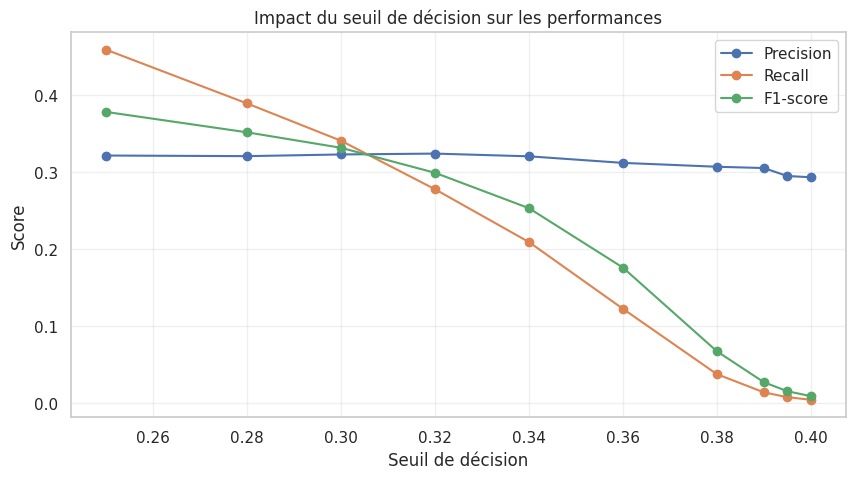

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(df_seuils["Seuil"], df_seuils["Precision"], marker="o", label="Precision")
plt.plot(df_seuils["Seuil"], df_seuils["Recall"], marker="o", label="Recall")
plt.plot(df_seuils["Seuil"], df_seuils["F1-score"], marker="o", label="F1-score")

plt.xlabel("Seuil de décision")
plt.ylabel("Score")
plt.title("Impact du seuil de décision sur les performances")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

La régression logistique présente une bonne capacité de discrimination, avec une ROC-AUC de 0,9434 et une Average Precision de 0,2716.

Cependant, le seuil de décision par défaut de 0,5 ne permet de détecter aucun événement positif. Une analyse de différents seuils montre qu'un seuil de 0,25 améliore sensiblement la détection, avec une précision de 0,322, un rappel de 0,459 et un F1-score de 0,379.

Le seuil de décision constitue donc un paramètre important pour adapter le modèle à l'objectif de détection préventive. Le seuil de 0,25 est conservé comme candidat pour les comparaisons ultérieures.

### Random Forest

Le modèle Random Forest repose sur un ensemble d'arbres de décision entraînés sur différentes sous-parties des données. Il permet de capturer des relations non linéaires et des interactions entre les variables.

Contrairement à la régression logistique, ce modèle ne nécessite pas de standardisation des variables. Une imputation des valeurs manquantes est néanmoins nécessaire.

Le modèle est entraîné sur le jeu d'entraînement, puis évalué sur le jeu de validation.

In [67]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

modele_rf = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("classification", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

modele_rf.fit(X_train, y_train)

y_pred_rf = modele_rf.predict(X_val)
y_proba_rf = modele_rf.predict_proba(X_val)[:, 1]

print("Entraînement du Random Forest terminé.")

Entraînement du Random Forest terminé.


 #### Évaluation des performances

In [68]:
print("Accuracy :", round(accuracy_score(y_val, y_pred_rf), 4))
print("Precision :", round(precision_score(y_val, y_pred_rf, zero_division=0), 4))
print("Recall :", round(recall_score(y_val, y_pred_rf, zero_division=0), 4))
print("F1-score :", round(f1_score(y_val, y_pred_rf, zero_division=0), 4))
print("Average Precision :", round(average_precision_score(y_val, y_proba_rf), 4))
print("ROC-AUC :", round(roc_auc_score(y_val, y_proba_rf), 4))

print("\nMatrice de confusion :")
print(confusion_matrix(y_val, y_pred_rf))

print("\nRapport de classification :")
print(classification_report(y_val, y_pred_rf, zero_division=0))

Accuracy : 0.961
Precision : 0.2809
Recall : 0.2015
F1-score : 0.2347
Average Precision : 0.225
ROC-AUC : 0.9061

Matrice de confusion :
[[377840   6050]
 [  9362   2363]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.98      0.98      0.98    383890
           1       0.28      0.20      0.23     11725

    accuracy                           0.96    395615
   macro avg       0.63      0.59      0.61    395615
weighted avg       0.96      0.96      0.96    395615



In [69]:
# Évaluation du Random Forest selon différents seuils

seuils_rf = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

resultats_rf = []

for seuil in seuils_rf:
    y_pred_seuil = (y_proba_rf >= seuil).astype(int)

    resultats_rf.append({
        "Seuil": seuil,
        "Precision": precision_score(y_val, y_pred_seuil, zero_division=0),
        "Recall": recall_score(y_val, y_pred_seuil, zero_division=0),
        "F1-score": f1_score(y_val, y_pred_seuil, zero_division=0),
        "Predictions positives": y_pred_seuil.sum()
    })

df_seuils_rf = pd.DataFrame(resultats_rf)

display(df_seuils_rf.round(4))

,Seuil,Precision,Recall,F1-score,Predictions positives
0,0.100,0.224,0.701,0.339,36701
1,0.150,0.249,0.613,0.355,28797
2,0.200,0.266,0.531,0.355,23383
3,0.250,0.276,0.458,0.345,19435
4,0.300,0.287,0.401,0.334,16381
5,0.350,0.293,0.345,0.317,13832
6,0.400,0.290,0.289,0.290,11665
7,0.450,0.286,0.243,0.263,9968
8,0.500,0.282,0.205,0.238,8524


L'ajustement du seuil de décision améliore les performances du Random Forest par rapport à son seuil par défaut de 0,5.

Le meilleur F1-score obtenu parmi les seuils testés est de 0,355, avec un seuil de 0,15 ou 0,20. Au seuil de 0,20, le modèle atteint une précision de 0,266 et un rappel de 0,531.

Ce résultat montre que le Random Forest permet de détecter davantage d'événements que la régression logistique avec les seuils candidats étudiés, mais génère également davantage de fausses alertes.

Le seuil de 0,20 est conservé comme candidat pour les comparaisons ultérieures.

### XGBoost

XGBoost est un algorithme de Gradient Boosting basé sur des arbres de décision. Les arbres sont construits successivement afin de corriger progressivement les erreurs du modèle.

Il est particulièrement adapté aux données tabulaires et permet de capturer des relations non linéaires ainsi que des interactions entre variables.

Le modèle sera entraîné sur les mêmes données que les modèles précédents afin de garantir une comparaison cohérente.

In [70]:
import xgboost as xgb

print("Version de XGBoost :", xgb.__version__)

Version de XGBoost : 3.4.1


In [71]:
from xgboost import XGBClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Calcul du poids de la classe positive
poids_positif = (y_train == 0).sum() / (y_train == 1).sum()

modele_xgb = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("classification", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=poids_positif,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    ))
])

modele_xgb.fit(X_train, y_train)

y_pred_xgb = modele_xgb.predict(X_val)
y_proba_xgb = modele_xgb.predict_proba(X_val)[:, 1]

print("Entraînement de XGBoost terminé.")

Entraînement de XGBoost terminé.


#### Évaluation des performances

In [72]:
print("Accuracy :", round(accuracy_score(y_val, y_pred_xgb), 4))
print("Precision :", round(precision_score(y_val, y_pred_xgb, zero_division=0), 4))
print("Recall :", round(recall_score(y_val, y_pred_xgb, zero_division=0), 4))
print("F1-score :", round(f1_score(y_val, y_pred_xgb, zero_division=0), 4))
print("Average Precision :", round(average_precision_score(y_val, y_proba_xgb), 4))
print("ROC-AUC :", round(roc_auc_score(y_val, y_proba_xgb), 4))

print("\nMatrice de confusion :")
print(confusion_matrix(y_val, y_pred_xgb))

print("\nRapport de classification :")
print(classification_report(y_val, y_pred_xgb, zero_division=0))

Accuracy : 0.8612
Precision : 0.1678
Recall : 0.9306
F1-score : 0.2844
Average Precision : 0.3563
ROC-AUC : 0.9527

Matrice de confusion :
[[329793  54097]
 [   814  10911]]

Rapport de classification :
              precision    recall  f1-score   support

           0       1.00      0.86      0.92    383890
           1       0.17      0.93      0.28     11725

    accuracy                           0.86    395615
   macro avg       0.58      0.89      0.60    395615
weighted avg       0.97      0.86      0.90    395615



In [73]:
# Évaluation de XGBoost selon différents seuils

seuils_xgb = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

resultats_xgb = []

for seuil in seuils_xgb:
    y_pred_seuil = (y_proba_xgb >= seuil).astype(int)

    resultats_xgb.append({
        "Seuil": seuil,
        "Precision": precision_score(y_val, y_pred_seuil, zero_division=0),
        "Recall": recall_score(y_val, y_pred_seuil, zero_division=0),
        "F1-score": f1_score(y_val, y_pred_seuil, zero_division=0),
        "Predictions positives": y_pred_seuil.sum()
    })

df_seuils_xgb = pd.DataFrame(resultats_xgb)

display(df_seuils_xgb.round(4))

,Seuil,Precision,Recall,F1-score,Predictions positives
0,0.300,0.141,0.966,0.246,80458
1,0.400,0.153,0.948,0.263,72765
2,0.500,0.168,0.931,0.284,65008
3,0.600,0.185,0.901,0.307,57128
4,0.700,0.209,0.856,0.336,47934
5,0.800,0.249,0.770,0.376,36284
6,0.900,0.333,0.563,0.418,19827


#### Affinement de la recherche du seuil XGBoost

In [74]:
# Affinement de la recherche du seuil XGBoost

seuils_xgb_fins = np.arange(0.90, 1.00, 0.01)

resultats_xgb_fins = []

for seuil in seuils_xgb_fins:
    y_pred_seuil = (y_proba_xgb >= seuil).astype(int)

    resultats_xgb_fins.append({
        "Seuil": seuil,
        "Precision": precision_score(y_val, y_pred_seuil, zero_division=0),
        "Recall": recall_score(y_val, y_pred_seuil, zero_division=0),
        "F1-score": f1_score(y_val, y_pred_seuil, zero_division=0),
        "Predictions positives": y_pred_seuil.sum()
    })

df_seuils_xgb_fins = pd.DataFrame(resultats_xgb_fins)

display(df_seuils_xgb_fins.round(4))

,Seuil,Precision,Recall,F1-score,Predictions positives
0,0.900,0.333,0.563,0.418,19827
1,0.910,0.353,0.507,0.416,16854
2,0.920,0.379,0.447,0.410,13846
3,0.930,0.411,0.376,0.393,10716
4,0.940,0.449,0.303,0.362,7927
5,0.950,0.479,0.247,0.326,6050
6,0.960,0.495,0.180,0.264,4258
7,0.970,0.535,0.058,0.104,1268
8,0.980,0.482,0.002,0.005,56
9,0.990,1.000,0.000,0.000,1


L'analyse comparative des trois modèles montre que XGBoost obtient les meilleures performances globales en matière de détection des stations susceptibles de devenir vides.

Avec un seuil de décision de 0,90, il atteint une précision de 0,333, un rappel de 0,563 et un F1-score de 0,418. Son Average Precision de 0,3563 et sa ROC-AUC de 0,9527 sont également supérieures à celles des deux autres modèles.

La régression logistique constitue une alternative intéressante, tandis que le Random Forest présente des performances plus limitées sur ce jeu de validation.

XGBoost est donc retenu comme modèle candidat prioritaire pour la phase d'optimisation des hyperparamètres.

# 8. Optimisation des hyperparamètres - XGBoost

On optimise les hyperparamètres de XGBoost qui a obtenu les meilleurs résultats lors de notre première comparaison.

### Création d'une validation temporelle interne

In [76]:
# Définition de la date de début de la validation interne
date_debut_val_interne = pd.Timestamp(
    "2026-10-28 00:00:00",
    tz="Europe/Paris"
)

marge = pd.Timedelta(minutes=30)

# Récupération des dates correspondant aux observations d'entraînement
temps_train = df_cible.loc[X_train.index, "temps"]

# Séparation chronologique avec une marge de 30 minutes
masque_train_interne = temps_train < date_debut_val_interne - marge
masque_val_interne = temps_train >= date_debut_val_interne

# Création des jeux de données
X_train_interne = X_train.loc[masque_train_interne].copy()
y_train_interne = y_train.loc[masque_train_interne].copy()

X_val_interne = X_train.loc[masque_val_interne].copy()
y_val_interne = y_train.loc[masque_val_interne].copy()

# Vérification des dimensions et de la répartition des classes
print("Dimensions des jeux de données :")
print("Entraînement interne :", X_train_interne.shape)
print("Validation interne   :", X_val_interne.shape)

print("\nTaux de positifs :")
print(f"Entraînement interne : {y_train_interne.mean() * 100:.2f} %")
print(f"Validation interne   : {y_val_interne.mean() * 100:.2f} %")

print("\nPériodes couvertes :")
print("Entraînement :", temps_train.loc[masque_train_interne].min(),
      "-->", temps_train.loc[masque_train_interne].max())
print("Validation  :", temps_train.loc[masque_val_interne].min(),
      "-->", temps_train.loc[masque_val_interne].max())

Dimensions des jeux de données :
Entraînement interne : (1216990, 23)
Validation interne   : (404563, 23)

Taux de positifs :
Entraînement interne : 3.05 %
Validation interne   : 3.10 %

Périodes couvertes :
Entraînement : 2026-10-25 00:00:00+02:00 --> 2026-10-27 23:25:00+01:00
Validation  : 2026-10-28 00:00:00+01:00 --> 2026-10-28 23:25:00+01:00


### Recherche des hyperparamètres de XGBoost

In [77]:
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score
from xgboost import XGBClassifier

# Imputation : apprentissage uniquement sur le jeu d'entraînement interne
imputation_xgb = SimpleImputer(strategy="median")

X_train_imp = imputation_xgb.fit_transform(X_train_interne)
X_val_imp = imputation_xgb.transform(X_val_interne)

# Gestion du déséquilibre des classes
poids_positif = (
    (y_train_interne == 0).sum() /
    (y_train_interne == 1).sum()
)

print(f"scale_pos_weight : {poids_positif:.2f}")

# Configurations à comparer
configurations = [
    {
        "n_estimators": 200,
        "max_depth": 6,
        "learning_rate": 0.1,
        "min_child_weight": 1,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1
    },
    {
        "n_estimators": 200,
        "max_depth": 4,
        "learning_rate": 0.1,
        "min_child_weight": 3,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1
    },
    {
        "n_estimators": 300,
        "max_depth": 5,
        "learning_rate": 0.05,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 5
    },
    {
        "n_estimators": 200,
        "max_depth": 7,
        "learning_rate": 0.1,
        "min_child_weight": 3,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1
    }
]

resultats_xgb = []
meilleur_ap = -1
meilleur_modele_xgb = None
meilleurs_parametres_xgb = None

# Entraînement et comparaison des configurations
for i, parametres in enumerate(configurations, start=1):

    print(f"\nConfiguration {i}/{len(configurations)}")

    modele = XGBClassifier(
        **parametres,
        scale_pos_weight=poids_positif,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    )

    modele.fit(X_train_imp, y_train_interne)

    probabilites = modele.predict_proba(X_val_imp)[:, 1]

    ap = average_precision_score(y_val_interne, probabilites)
    roc_auc = roc_auc_score(y_val_interne, probabilites)

    resultats_xgb.append({
        "configuration": i,
        "AP": ap,
        "ROC-AUC": roc_auc
    })

    print(f"AP      : {ap:.4f}")
    print(f"ROC-AUC : {roc_auc:.4f}")

    if ap > meilleur_ap:
        meilleur_ap = ap
        meilleur_modele_xgb = modele
        meilleurs_parametres_xgb = parametres.copy()

# Tableau comparatif
resultats_xgb = pd.DataFrame(resultats_xgb)
resultats_xgb = resultats_xgb.sort_values(
    "AP",
    ascending=False
).reset_index(drop=True)

print("\nRésultats comparatifs :")
display(resultats_xgb)

print("\nMeilleurs paramètres :")
print(meilleurs_parametres_xgb)

scale_pos_weight : 31.82

Configuration 1/4
AP      : 0.3623
ROC-AUC : 0.9531

Configuration 2/4
AP      : 0.3598
ROC-AUC : 0.9538

Configuration 3/4
AP      : 0.3625
ROC-AUC : 0.9538

Configuration 4/4
AP      : 0.3598
ROC-AUC : 0.9524

Résultats comparatifs :


,configuration,AP,ROC-AUC
0,3,0.362,0.954
1,1,0.362,0.953
2,4,0.360,0.952
3,2,0.360,0.954



Meilleurs paramètres :
{'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.05, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 5}


## Réentraînement du modèle optimisé et évaluation

In [78]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

# Imputation ajustée sur l'intégralité du jeu d'entraînement
imputation_xgb_final = SimpleImputer(strategy="median")

X_train_imp_final = imputation_xgb_final.fit_transform(X_train)
X_val_imp_final = imputation_xgb_final.transform(X_val)

# Recalcul du poids de la classe positive sur tout l'entraînement
poids_positif_final = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

# Création du modèle avec les meilleurs paramètres
modele_xgb_optimise = XGBClassifier(
    **meilleurs_parametres_xgb,
    scale_pos_weight=poids_positif_final,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

# Entraînement
modele_xgb_optimise.fit(X_train_imp_final, y_train)

# Prédictions sur la validation externe (29 octobre)
y_proba_xgb_optimise = modele_xgb_optimise.predict_proba(
    X_val_imp_final
)[:, 1]

# Métriques indépendantes du seuil
ap_optimise = average_precision_score(
    y_val, y_proba_xgb_optimise
)

roc_optimise = roc_auc_score(
    y_val, y_proba_xgb_optimise
)

print(f"Average Precision : {ap_optimise:.4f}")
print(f"ROC-AUC            : {roc_optimise:.4f}")

Average Precision : 0.3611
ROC-AUC            : 0.9536


In [79]:
seuils = [0.50, 0.70, 0.80, 0.85, 0.90, 0.92, 0.94, 0.95]

resultats_seuils = []

for seuil in seuils:

    y_pred = (y_proba_xgb_optimise >= seuil).astype(int)

    resultats_seuils.append({
        "Seuil": seuil,
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "Predictions positives": y_pred.sum()
    })

table_seuils_optimise = pd.DataFrame(resultats_seuils)

display(
    table_seuils_optimise.round(4)
)

,Seuil,Precision,Recall,F1,Predictions positives
0,0.500,0.163,0.943,0.277,67975
1,0.700,0.206,0.867,0.333,49245
2,0.800,0.249,0.777,0.377,36640
3,0.850,0.288,0.689,0.406,28071
4,0.900,0.326,0.570,0.415,20529
5,0.920,0.381,0.445,0.411,13673
6,0.940,0.459,0.289,0.355,7390
7,0.950,0.487,0.229,0.311,5504


L'optimisation des hyperparamètres de XGBoost a permis d'améliorer légèrement
les performances de classement du modèle.

Sur la validation externe du 29 octobre, le modèle optimisé obtient un
Average Precision de 0,3611 et un ROC-AUC de 0,9536, contre respectivement
0,3563 et 0,9527 pour le modèle initial.

Le meilleur F1 parmi les seuils testés est de 0,415 pour un seuil de 0,90,
avec une précision de 0,326 et un rappel de 0,570.

Le modèle optimisé est conservé comme candidat pour la comparaison finale.

# 9. Évaluation et comparaison finale des modèles

### Constitution du tableau comparatif

Pour éviter de mélanger les seuils, nous allons utiliser les meilleurs seuils F1 identifiés lors de nos essais précédents :
- Régression logistique : 0,25.
- Random Forest : 0,20.
- XGBoost initial : 0,90.
- XGBoost optimisé : 0,90.

In [80]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

# Modèles et probabilités déjà calculées sur la validation du 29 octobre
modeles_comparaison = {
    "Régression logistique": {
        "probabilites": y_proba_log,
        "seuil": 0.25
    },
    "Random Forest": {
        "probabilites": y_proba_rf,
        "seuil": 0.20
    },
    "XGBoost initial": {
        "probabilites": y_proba_xgb,
        "seuil": 0.90
    },
    "XGBoost optimisé": {
        "probabilites": y_proba_xgb_optimise,
        "seuil": 0.90
    }
}

resultats_comparaison = []

for nom, infos in modeles_comparaison.items():

    probabilites = infos["probabilites"]
    seuil = infos["seuil"]

    predictions = (probabilites >= seuil).astype(int)

    resultats_comparaison.append({
        "Modèle": nom,
        "Seuil": seuil,
        "AP": average_precision_score(y_val, probabilites),
        "ROC-AUC": roc_auc_score(y_val, probabilites),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "Prédictions positives": predictions.sum()
    })

df_comparaison = pd.DataFrame(resultats_comparaison)

df_comparaison = df_comparaison.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

display(df_comparaison.round(4))

,Modèle,Seuil,AP,ROC-AUC,Precision,Recall,F1,Prédictions positives
0,XGBoost initial,0.900,0.356,0.953,0.333,0.563,0.418,19827
1,XGBoost optimisé,0.900,0.361,0.954,0.326,0.570,0.415,20529
2,Régression logistique,0.250,0.272,0.943,0.322,0.459,0.379,16727
3,Random Forest,0.200,0.225,0.906,0.266,0.531,0.355,23383


### Conclusion de la comparaison

La comparaison des quatre modèles montre que XGBoost obtient les meilleures
performances globales.

Le modèle XGBoost initial présente le meilleur F1-score (0,418) et la
meilleure précision (0,333), avec un rappel de 0,563 pour un seuil de 0,90.

Le modèle XGBoost optimisé obtient le meilleur Average Precision (0,3611)
et le meilleur ROC-AUC (0,9536), ainsi qu'un rappel légèrement supérieur
(0,570).

Les deux modèles présentent des performances proches. Le XGBoost initial
est conservé comme premier candidat en raison de son meilleur compromis
entre précision et rappel, tandis que le modèle optimisé reste une
alternative intéressante.

# 10. Sélection du meilleur modèle et test final

### Évaluation sur le jeu de test (30 octobre)

Le test du 30 octobre n'a encore jamais été utilisé pour entraîner, optimiser ou sélectionner les modèles. Nous allons maintenant l'utiliser pour mesurer les performances finales.

In [81]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

# Imputation sur l'entraînement uniquement
imputation_xgb_test = SimpleImputer(strategy="median")

X_train_imp_test = imputation_xgb_test.fit_transform(X_train)
X_test_imp = imputation_xgb_test.transform(X_test)

# Entraînement du XGBoost initial sur l'ensemble du train
poids_positif_test = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

modele_final = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=poids_positif_test,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

modele_final.fit(X_train_imp_test, y_train)

# Prédictions sur le jeu de test
y_proba_test = modele_final.predict_proba(X_test_imp)[:, 1]

# Seuil fixé avant l'évaluation finale
seuil_final = 0.90
y_pred_test = (y_proba_test >= seuil_final).astype(int)

# Évaluation
print("MÉTRIQUES SUR LE JEU DE TEST")
print("----------------------------")

print(f"Average Precision : {average_precision_score(y_test, y_proba_test):.4f}")
print(f"ROC-AUC           : {roc_auc_score(y_test, y_proba_test):.4f}")
print(f"Precision         : {precision_score(y_test, y_pred_test):.4f}")
print(f"Recall            : {recall_score(y_test, y_pred_test):.4f}")
print(f"F1-score          : {f1_score(y_test, y_pred_test):.4f}")

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_test))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_test, digits=4))

MÉTRIQUES SUR LE JEU DE TEST
----------------------------
Average Precision : 0.3216
ROC-AUC           : 0.9463
Precision         : 0.3325
Recall            : 0.4845
F1-score          : 0.3944

Matrice de confusion :
[[365585   9901]
 [  5247   4932]]

Rapport de classification :
              precision    recall  f1-score   support

           0     0.9859    0.9736    0.9797    375486
           1     0.3325    0.4845    0.3944     10179

    accuracy                         0.9607    385665
   macro avg     0.6592    0.7291    0.6870    385665
weighted avg     0.9686    0.9607    0.9643    385665



### Évaluation finale sur le jeu de test

Le modèle XGBoost initial a été réentraîné sur l'ensemble du jeu
d'entraînement, puis évalué sur le jeu de test
du 30 octobre, qui n'avait pas été utilisé lors des étapes précédentes.

Avec un seuil de décision fixé à 0,90, les résultats obtenus sont :

- Average Precision : 0,3216
- ROC-AUC : 0,9463
- Precision : 0,3325
- Recall : 0,4845
- F1-score : 0,3944

Le modèle détecte 4 932 événements sur les 10 179 événements
réellement observés, soit un rappel de 48,45 %.

Cependant, 9 901 fausses alertes sont également générées,
ce qui traduit une précision de 33,25 %.

Les performances restent satisfaisantes en termes de discrimination,
mais la baisse du rappel entre la validation et le test montre que
la capacité de détection varie selon la journée observée.

Le modèle est donc capable d'identifier une partie significative
des stations à risque, mais des améliorations restent nécessaires
pour limiter les fausses alertes et mieux détecter les événements.

# 11. Interprétabilité et analyse des erreurs

### Importance des variables avec XGBoost

XGBoost permet d'extraire directement l'importance des variables utilisées dans ses arbres de décision.

Nous allons commencer par feature_importances_, qui fournit une première indication de leur contribution au modèle.

In [82]:
# Extraction de l'importance des variables
importances = modele_final.feature_importances_

# Création du tableau des importances
df_importances = pd.DataFrame({
    "Variable": X_train.columns,
    "Importance": importances
})

# Classement par ordre décroissant
df_importances = df_importances.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(df_importances.round(4))

,Variable,Importance
0,velos,0.656
1,velos_moins_5min,0.125
2,taux_disponibilite,0.038
3,heure,0.026
4,weekend,0.014
5,heure_cos,0.014
6,moyenne_velos_3_releves,0.013
7,variation_velos_5min,0.012
8,heure_sin,0.010
9,variation_velos_15min,0.010


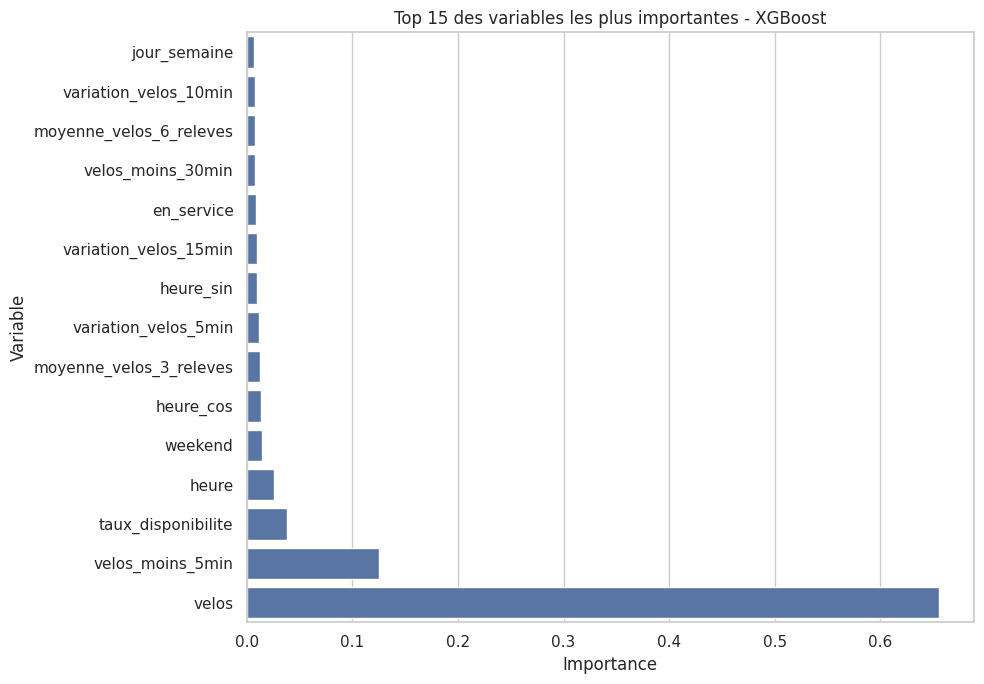

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns

top_variables = df_importances.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_variables,
    x="Importance",
    y="Variable"
)

plt.title("Top 15 des variables les plus importantes - XGBoost")
plt.xlabel("Importance")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

L'analyse de l'importance des variables montre que le nombre de vélos
disponibles au moment de la prédiction (`velos`) constitue le principal
facteur utilisé par le modèle, avec une importance de 65,6 %.

Le nombre de vélos observé cinq minutes auparavant (`velos_moins_5min`)
arrive en deuxième position avec 12,5 %, suivi du taux de disponibilité
avec 3,8 %.

Les variables temporelles, notamment l'heure et l'indicateur de week-end,
apportent également des informations complémentaires.

Ces résultats montrent que le modèle s'appuie principalement sur l'état
actuel de la station et son évolution récente pour anticiper les risques
de disponibilité nulle.

Il s'agit d'une mesure d'importance interne au modèle et non d'une mesure
de causalité ou du sens de l'influence des variables.

### Analyse des erreurs de prédiction

In [84]:
# Création d'un tableau regroupant les observations du test
df_erreurs = X_test.copy()

df_erreurs["target_reelle"] = y_test
df_erreurs["prediction"] = y_pred_test
df_erreurs["probabilite"] = y_proba_test

# Identification des types de prédictions
df_erreurs["type_prediction"] = "TN"

df_erreurs.loc[
    (df_erreurs["target_reelle"] == 1) &
    (df_erreurs["prediction"] == 1),
    "type_prediction"
] = "TP"

df_erreurs.loc[
    (df_erreurs["target_reelle"] == 0) &
    (df_erreurs["prediction"] == 1),
    "type_prediction"
] = "FP"

df_erreurs.loc[
    (df_erreurs["target_reelle"] == 1) &
    (df_erreurs["prediction"] == 0),
    "type_prediction"
] = "FN"

# Répartition des erreurs
print("Répartition des prédictions :")
display(
    df_erreurs["type_prediction"]
    .value_counts()
    .rename_axis("Type")
    .to_frame("Nombre")
)

# Analyse des faux négatifs et des faux positifs
df_analyse_erreurs = (
    df_erreurs[df_erreurs["type_prediction"].isin(["FN", "FP"])]
    .groupby("type_prediction")
    .agg(
        nombre=("target_reelle", "size"),
        moyenne_velos=("velos", "mean"),
        mediane_velos=("velos", "median"),
        moyenne_taux_disponibilite=("taux_disponibilite", "mean"),
        moyenne_probabilite=("probabilite", "mean")
    )
)

display(df_analyse_erreurs.round(3))

Répartition des prédictions :


,Nombre
Type,
TN,365585
FP,9901
FN,5247
TP,4932


,nombre,moyenne_velos,mediane_velos,moyenne_taux_disponibilite,moyenne_probabilite
type_prediction,,,,,
FN,5247,2.683,2.000,0.103,0.658
FP,9901,1.142,1.000,0.046,0.932


L'analyse des erreurs montre que les faux positifs et les faux négatifs
concernent principalement des stations présentant déjà une faible
disponibilité en vélos.

Les faux négatifs disposent en moyenne de 2,68 vélos au moment de la
prédiction, tandis que les faux positifs en disposent de 1,14.

Le modèle détecte donc des situations de faible disponibilité, mais
rencontre des difficultés pour distinguer les stations qui deviendront
effectivement vides dans les 30 prochaines minutes de celles qui
conserveront au moins un vélo.

Ces résultats montrent que l'état courant de la station ne suffit pas
toujours à anticiper précisément l'évolution de sa disponibilité.

### Comparaison des vrais positifs et des faux négatifs

In [85]:
# Comparaison des vrais positifs et des faux négatifs
df_comparaison_erreurs = (
    df_erreurs[df_erreurs["type_prediction"].isin(["TP", "FN"])]
    .groupby("type_prediction")
    .agg(
        nombre=("velos", "size"),
        velos_actuels=("velos", "mean"),
        velos_5min=("velos_moins_5min", "mean"),
        velos_10min=("velos_moins_10min", "mean"),
        velos_15min=("velos_moins_15min", "mean"),
        variation_5min=("variation_velos_5min", "mean"),
        variation_15min=("variation_velos_15min", "mean"),
        probabilite=("probabilite", "mean")
    )
)

display(df_comparaison_erreurs.round(3))

,nombre,velos_actuels,velos_5min,velos_10min,velos_15min,variation_5min,variation_15min,probabilite
type_prediction,,,,,,,,
FN,5247,2.683,2.822,2.932,3.029,-0.138,-0.331,0.658
TP,4932,1.091,1.123,1.177,1.232,-0.031,-0.138,0.940


La comparaison des vrais positifs et des faux négatifs montre que le
modèle détecte plus facilement les stations déjà proches de l'épuisement
de leur stock.

Les événements correctement détectés concernent des stations disposant
en moyenne de 1,09 vélo au moment de la prédiction. À l'inverse, les
événements manqués concernent des stations disposant encore de 2,68 vélos.

Une diminution progressive du nombre de vélos est observée dans les deux
groupes. Cependant, le modèle attribue une probabilité moyenne de 65,8 %
aux événements manqués, contre 94 % aux événements correctement détectés.

Le modèle est donc davantage performant pour identifier les situations
de disponibilité critique que pour anticiper suffisamment tôt les
épuisements de stock.

## 12. Conclusion générale

### Objectif

Ce projet avait pour objectif de développer un modèle de classification
capable de prédire si une station Vélib' allait devenir vide au cours
des 30 prochaines minutes, à partir des relevés historiques de
disponibilité.

### Démarche

La démarche a suivi plusieurs étapes :
- Exploration et vérification de la qualité des données.
- Construction de la variable cible à partir des six relevés futurs.
- Création de variables temporelles, de disponibilité et d'évolution
  historique du nombre de vélos.
- Séparation chronologique des données en ensembles d'entraînement,
  de validation et de test, avec une marge de 30 minutes aux frontières.
- Entraînement et comparaison de plusieurs modèles : Dummy Classifier,
  régression logistique, Random Forest et XGBoost.
- Optimisation des hyperparamètres et sélection du modèle final.
- Évaluation indépendante sur les données du 30 octobre 2026.
- Analyse de l'importance des variables et des erreurs de prédiction.

### Résultats

Le modèle XGBoost initial a été retenu avec un seuil de décision fixé
à 0,90.

Sur le jeu de test, il obtient :
- Average Precision : 0,3216
- ROC-AUC : 0,9463
- Précision : 0,3325
- Rappel : 0,4845
- F1-score : 0,3944

Le modèle a correctement détecté 4 932 événements sur les 10 179
événements réellement observés, soit un rappel de 48,45 %.

L'analyse des variables montre que le nombre de vélos disponibles au
moment de la prédiction est le facteur le plus important pour le modèle.
Les relevés historiques récents et les variables temporelles apportent
également de l'information.

### Limites et perspectives

Plusieurs limites doivent être prises en compte :
- La période d'observation est relativement courte, puisqu'elle couvre
  seulement six jours.
- La classe positive est minoritaire, représentant environ 3 % des
  observations.
- Le modèle génère encore un nombre important de fausses alertes et
  manque une partie des événements.
- Il anticipe plus facilement les stations déjà presque vides que celles
  dont le stock diminue progressivement.

Pour améliorer les performances, plusieurs pistes peuvent être étudiées :
- Collecter des données sur une période plus longue afin de couvrir
  davantage de comportements et de conditions d'utilisation.
- Intégrer des informations météorologiques, géographiques et sur les
  flux de déplacements.
- Étudier des seuils de décision adaptés aux besoins opérationnels,
  selon le compromis souhaité entre précision et rappel.
- Explorer des approches permettant de mieux anticiper la dynamique
  de disponibilité des stations.

### Bilan

Ce projet a permis de développer une solution prédictive capable de déterminer si une station Vélib' va devenir vide au cours des 30 prochaines minutes.

Les résultats montrent que les données de disponibilité et leur
historique contiennent un signal prédictif intéressant. Toutefois,
une période d'observation plus longue et l'intégration de nouvelles
informations seront nécessaires pour renforcer la fiabilité du modèle
et envisager son utilisation dans un contexte opérationnel.